# Lab 2 — Unified CNN Exploration

**What:** One reproducible notebook connecting grayscale medical images, RGB natural images, learned CNN features, and LeNet-5.

**Why:** The same convolution ideas become clearer when we compare hand-crafted filters, random kernels, and trained features while tracking shape, complexity, padding, receptive field, and representation changes.

## Additional learning included in this notebook

- **Filter mathematics:** multiple kernel sizes and filter types; user-defined correlation; true convolution by flipping; `same`, `valid`, and border-padding effects.
- **Implementation comparison:** identical kernel/input passed through the custom function and built-in Keras `Conv2D`, with numerical error and visual side-by-side comparison.
- **Layer-by-layer tracing:** input → convolution/ReLU → pooling → convolution/ReLU → pooling → flatten → latent vector → classifier, with shapes, maps, discarded pooling detail, kernels, and outputs.
- **RGB analysis:** R/G/B channel filters, annotated kernel weights, full 3-channel convolution, random versus learned features, and edge/texture/shape/semantic comparisons.
- **Complexity and geometry:** parameters, activations, MACs, spatial resolution, stride, and receptive-field growth.
- **Interpretability:** Grad-CAM, flattened-vector and softmax plots, a feature-hierarchy comparison, and a final CNN pipeline poster.
- **Part B additions:** historical LeNet-5 versus tuned LeNet-5, layer trace, hyperparameter safeguards, and a final source-to-requirement audit.

Each major code block starts with a one-line **What** statement followed by **Why** it was included.


## Conventions and execution notes

- **What/Why:** Every section states what it does and why it matters.
- **Shapes:** Images use `(batch, height, width, channels)`; latent vectors use `(batch, features)`.
- **Feature vocabulary:** *hand-crafted* = fixed human-designed kernels; *random* = untrained initialized kernels; *learned* = weights updated from data.
- **Data safety:** validation is split from training data; test data is held out for final evaluation.
- **Optional resources:** TissueMNIST, KerasTuner, and ImageNet weights have explicit fallback messages instead of silent failure.
- Run this notebook from this directory in the linked project venv so `sons_of_anarchy.jpg` resolves relatively.

## Advanced-analysis checklist

- [x] Prove the cross-correlation/convolution distinction and document why deep-learning libraries use correlation.
- [x] Track receptive field and feature-map jump through convolution/pooling stages.
- [x] Compare learned first-layer kernels against Sobel/Gaussian priors, including RGB channel mixing.
- [x] Inspect a lightweight Grad-CAM explanation when a trained model is available.
- [x] Cluster 500 MNIST latent vectors with PCA and bounded t-SNE.
- [x] Report per-class precision/recall/F1 and visualize the highest-confidence mistakes.
- [x] Compare parameter count with approximate multiply-accumulate (MAC) cost across CNN families.

All advanced sections below are bounded and guarded so the notebook remains readable when optional datasets, tuned models, or ImageNet weights are unavailable.

## Correlation, true convolution, and receptive fields

For a 2-D input $x$ and kernel $k$ with support $K$, a deep-learning `Conv2D` layer computes **cross-correlation**:

$$
(x \star k)[i,j] = \sum_{(u,v)\in K} x[i+u,j+v]k[u,v].
$$

Mathematical convolution flips the kernel in both spatial axes:

$$
(x * k)[i,j] = \sum_{(u,v)\in K}x[i-u,j-v]k[u,v]
                 = \sum_{(u,v)\in K}x[i+u,j+v]k[-u,-v]
                 = (x\star\operatorname{flip}_{180}(k))[i,j].
$$

Thus correlation and convolution agree for centrosymmetric kernels (for example, an ideal Gaussian), but an oriented Sobel kernel changes edge polarity after the flip. In modern deep learning this naming choice is harmless: the kernel is learned from data, so a learned filter can absorb a fixed 180° reparameterization. Avoiding the flip also gives a simpler, faster memory access pattern and matches the convention used by common tensor libraries.

For layer $l$, let $R_l$ be the input-space receptive-field width and $J_l$ the spacing (jump) between neighboring activations. With kernel width $k_l$ and stride $s_l$:

$$R_l=R_{l-1}+(k_l-1)J_{l-1},\qquad J_l=J_{l-1}s_l,$$

initialized with $R_0=J_0=1$. Pooling uses the same update with its pool width in place of $k_l$.

| stage | operation | $k_l$ | $s_l$ | receptive field $R_l$ | jump $J_l$ |
|---|---|---:|---:|---:|---:|
| input | pixels | — | — | 1 | 1 |
| 1 | $3\times3$ conv | 3 | 1 | 3 | 1 |
| 2 | $2\times2$ pool | 2 | 2 | 4 | 2 |
| 3 | $3\times3$ conv | 3 | 1 | 8 | 2 |
| 4 | $2\times2$ pool | 2 | 2 | 10 | 4 |

```text
input pixels ──[ 3×3 conv ]── R=3,J=1 ──[ 2×2 pool ]── R=4,J=2
                                      └──[ 3×3 conv ]── R=8,J=2 ──[ 2×2 pool ]── R=10,J=4
```


In [1]:
import os, random, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
SEED=42
os.environ["PYTHONHASHSEED"]=str(SEED); random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
ROOT=Path.cwd(); IMAGE_PATH=ROOT/"sons_of_anarchy.jpg"
print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__}"); print(f"Working directory: {ROOT}")
assert IMAGE_PATH.exists(), f"Expected relative image path: {IMAGE_PATH}"

Python 3.14.6 | TensorFlow 2.22.0-rc0
Working directory: /Users/dan/projects/pythonVishal/machine_learning/applied_machine_oil/lab2


## Shared helpers

**What:** Define one arbitrary odd-kernel correlation helper, a true-convolution wrapper, plotting helpers, and complexity/receptive-field calculations.

**Why:** Keeping these primitives shared prevents duplicated logic and makes manual versus built-in operations explicit.

In [2]:
def apply_odd_kernel(image,kernel,padding="reflect"):
    image=np.asarray(image,dtype=np.float32); kernel=np.asarray(kernel,dtype=np.float32)
    assert image.ndim==2 and kernel.ndim==2 and kernel.shape[0]==kernel.shape[1] and kernel.shape[0]%2==1
    radius=kernel.shape[0]//2; padded=np.pad(image,radius,mode=padding)
    return np.array([[np.sum(padded[r:r+2*radius+1,c:c+2*radius+1]*kernel) for c in range(image.shape[1])] for r in range(image.shape[0])],dtype=np.float32)
def true_convolution(image,kernel,padding="reflect"):
    return apply_odd_kernel(image,np.flip(np.asarray(kernel),axis=(0,1)),padding)
def show_maps(images,titles,cmap="viridis",cols=4,figsize=None):
    images=list(images); rows=int(np.ceil(len(images)/cols)); fig,axes=plt.subplots(rows,cols,figsize=figsize or (3.2*cols,3*rows),squeeze=False)
    for ax,image,title in zip(axes.ravel(),images,titles): ax.imshow(image,cmap=cmap); ax.set_title(f"{title}\n{np.shape(image)}"); ax.axis("off")
    for ax in axes.ravel()[len(images):]: ax.axis("off")
    plt.tight_layout(); return fig
def cnn_complexity(model,input_shape):
    x=tf.zeros((1,*input_shape)); rows=[]; receptive=jump=1
    for layer in model.layers:
        before=x; x=layer(x,training=False); shape=tuple(int(v) for v in x.shape[1:]); macs=0
        if isinstance(layer,tf.keras.layers.Conv2D):
            kh,kw=layer.kernel_size; macs=int(np.prod(shape)*kh*kw*int(before.shape[-1])); receptive+=(kh-1)*jump; jump*=layer.strides[0]
        elif isinstance(layer,(tf.keras.layers.MaxPooling2D,tf.keras.layers.AveragePooling2D)):
            ph,pw=layer.pool_size; receptive+=(ph-1)*jump; jump*=layer.strides[0]
        elif isinstance(layer,tf.keras.layers.Dense): macs=int(before.shape[-1])*layer.units
        rows.append({"layer":layer.name,"output_shape":shape,"parameters":layer.count_params(),"activations":int(np.prod(shape)),"approx_MACs":macs,"receptive_field":receptive,"jump":jump})
    return pd.DataFrame(rows)

# Part A1 — TissueMNIST (grayscale)

**What:** Load TissueMNIST through `medmnist`, normalize grayscale images, compare fixed filters with correlation/true convolution, then train a compact CNN.

**Why:** A medical grayscale tensor makes channel handling and early feature extraction easy to inspect before moving to RGB.

In [3]:
try:
    import medmnist
    from medmnist import INFO, TissueMNIST
    tissue_available=True; print("medmnist available:",medmnist.__version__)
except Exception as exc:
    tissue_available=False; print("TissueMNIST unavailable; install medmnist in the linked venv to run A1:",exc)

medmnist available: 3.0.2


We use the BBBC051, available from the Broad Bioimage Benchmark Collection. The dataset contains 236,386 human kidney cortex cells, segmented from 3 reference tissue specimens and organized into 8 categories. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. Each gray-scale image is 32×32×7 pixels, where 7 denotes 7 slices. We take maximum values across the slices and resize them into 28×28 gray-scale images.
(165466, 28, 28, 1) (23640, 28, 28, 1) (47280, 28, 28, 1) classes: 8


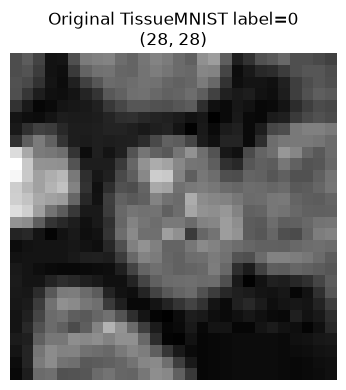

In [4]:
if tissue_available:
    info=INFO["tissuemnist"]; tissue_classes=len(info["label"])
    def med_arrays(ds):
        images=np.asarray(ds.imgs,dtype=np.float32)/255.0; labels=np.asarray(ds.labels).reshape(-1).astype("int64")
        if images.ndim==3: images=images[...,None]
        return images,labels
    tissue_train,tissue_y_train=med_arrays(TissueMNIST(split="train",download=True)); tissue_val,tissue_y_val=med_arrays(TissueMNIST(split="val",download=True)); tissue_test,tissue_y_test=med_arrays(TissueMNIST(split="test",download=True))
    print(info["description"]); print(tissue_train.shape,tissue_val.shape,tissue_test.shape,"classes:",tissue_classes)
    assert tissue_train.shape[-1]==1 and tissue_train.dtype==np.float32
    show_maps([tissue_train[0,...,0]],[f"Original TissueMNIST label={tissue_y_train[0]}"],cmap="gray",cols=1,figsize=(4,4))
else:
    tissue_train=tissue_val=tissue_test=tissue_y_train=tissue_y_val=tissue_y_test=None

Correlation vs true convolution mean absolute difference: 0.40741297602653503


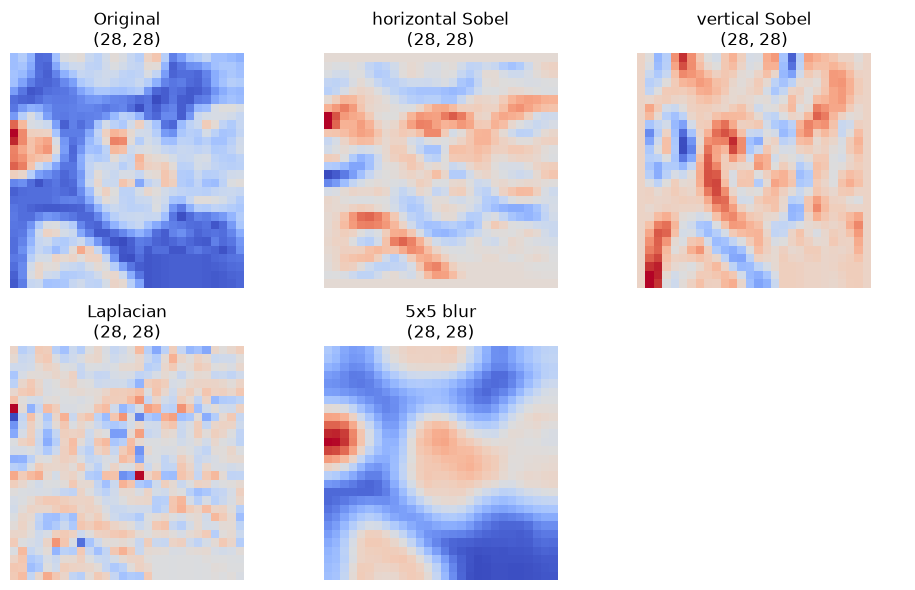

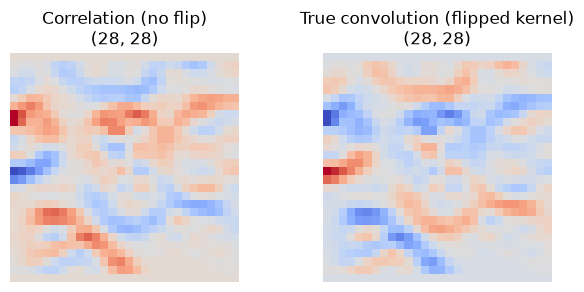

In [5]:
TISSUE_FILTERS={"horizontal Sobel":np.array([[-1,-2,-1],[0,0,0],[1,2,1]],np.float32),"vertical Sobel":np.array([[-1,0,1],[-2,0,2],[-1,0,1]],np.float32),"Laplacian":np.array([[0,1,0],[1,-4,1],[0,1,0]],np.float32),"5x5 blur":np.ones((5,5),np.float32)/25}
if tissue_available:
    sample_gray=tissue_train[0,...,0]; fixed={n:apply_odd_kernel(sample_gray,k) for n,k in TISSUE_FILTERS.items()}
    show_maps([sample_gray,*fixed.values()],["Original",*fixed.keys()],cmap="coolwarm",cols=3)
    kernel=TISSUE_FILTERS["horizontal Sobel"]; corr=apply_odd_kernel(sample_gray,kernel); conv=true_convolution(sample_gray,kernel)
    print("Correlation vs true convolution mean absolute difference:",float(np.mean(np.abs(corr-conv)))); assert corr.shape==conv.shape==sample_gray.shape
    show_maps([corr,conv],["Correlation (no flip)","True convolution (flipped kernel)"],cmap="coolwarm",cols=2)

### Built-in Conv2D comparison

**What:** Put the same fixed kernel into a Keras `Conv2D` layer and compare it with manual correlation.

**Why:** TensorFlow calls the layer Conv2D, but its forward operation is cross-correlation unless weights are spatially flipped.

In [6]:
if tissue_available:
    conv_fixed=tf.keras.layers.Conv2D(1,3,padding="same",use_bias=False,kernel_initializer="zeros"); _=conv_fixed(tissue_train[:1])
    conv_fixed.set_weights([TISSUE_FILTERS["horizontal Sobel"][...,None,None]])
    keras_response=conv_fixed(tissue_train[:1]).numpy()[0,...,0]; manual_response=apply_odd_kernel(sample_gray,TISSUE_FILTERS["horizontal Sobel"],padding="constant")
    print("Built-in/manual max error:",float(np.max(np.abs(keras_response-manual_response)))); assert keras_response.shape==manual_response.shape

Built-in/manual max error: 1.1920928955078125e-07


### Small learned TissueMNIST CNN

**What:** Train a short CNN and trace convolution, pooling, flatten, and latent activations.

**Why:** Learned maps differ from fixed Sobel/blur responses because their weights are optimized for classification.

Epoch 1/2


1293/1293 - 18s - 14ms/step - accuracy: 0.4791 - loss: 1.4235 - val_accuracy: 0.5162 - val_loss: 1.3154


Epoch 2/2


1293/1293 - 19s - 14ms/step - accuracy: 0.5252 - loss: 1.2857 - val_accuracy: 0.5335 - val_loss: 1.2644


Tissue test: [1.2602707147598267, 0.536653995513916]
tissue_conv1 (1, 28, 28, 8)
tissue_pool1 (1, 14, 14, 8)
tissue_conv2 (1, 14, 14, 16)
tissue_pool2 (1, 7, 7, 16)
tissue_flatten (1, 784)
tissue_latent (1, 32)


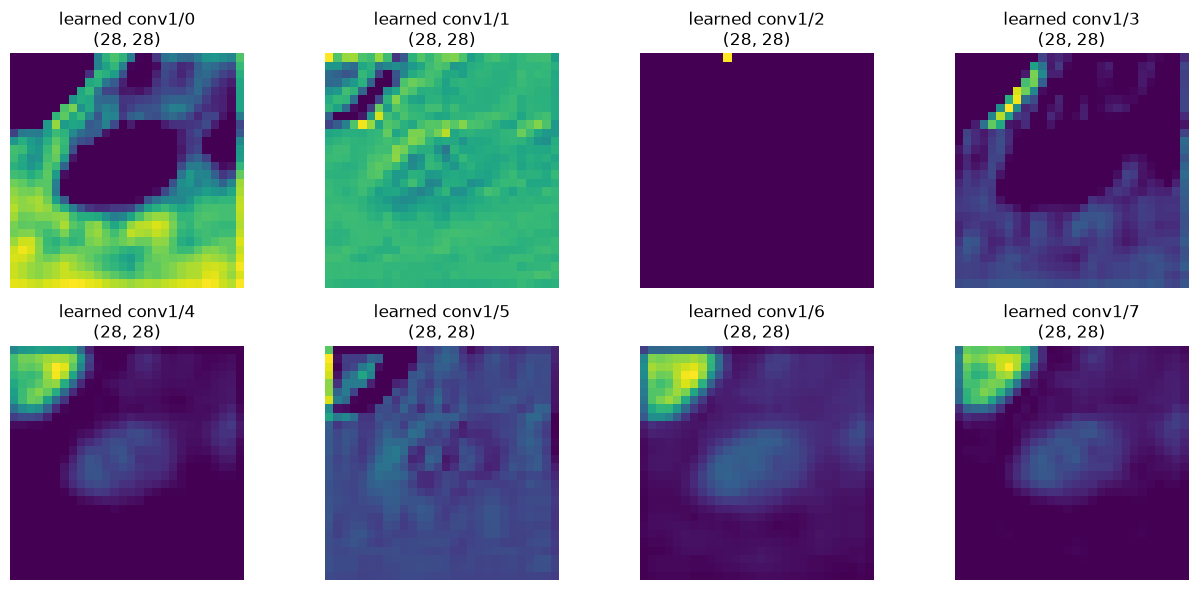

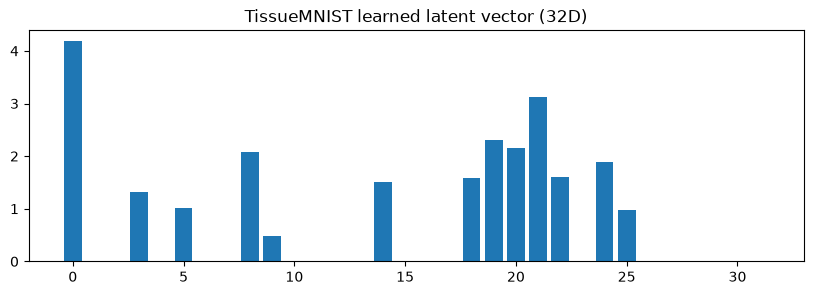

In [7]:
if tissue_available:
    tissue_model=tf.keras.Sequential([tf.keras.layers.Input(tissue_train.shape[1:]),tf.keras.layers.Conv2D(8,3,padding="same",activation="relu",name="tissue_conv1"),tf.keras.layers.MaxPooling2D(2,name="tissue_pool1"),tf.keras.layers.Conv2D(16,3,padding="same",activation="relu",name="tissue_conv2"),tf.keras.layers.MaxPooling2D(2,name="tissue_pool2"),tf.keras.layers.Flatten(name="tissue_flatten"),tf.keras.layers.Dense(32,activation="relu",name="tissue_latent"),tf.keras.layers.Dense(tissue_classes,activation="softmax",name="tissue_classifier")])
    tissue_model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]); tissue_model.fit(tissue_train,tissue_y_train,validation_data=(tissue_val,tissue_y_val),epochs=2,batch_size=128,verbose=2)
    print("Tissue test:",tissue_model.evaluate(tissue_test,tissue_y_test,verbose=0)); names=["tissue_conv1","tissue_pool1","tissue_conv2","tissue_pool2","tissue_flatten","tissue_latent"]; trace=tf.keras.Model(tissue_model.inputs[0],[tissue_model.get_layer(n).output for n in names]); acts=dict(zip(names,trace.predict(tissue_test[:1],verbose=0)))
    for n in names: print(n,acts[n].shape)
    show_maps([acts["tissue_conv1"][0,...,i] for i in range(8)],[f"learned conv1/{i}" for i in range(8)],cols=4)
    plt.figure(figsize=(10,3)); plt.bar(np.arange(acts["tissue_latent"].shape[-1]),acts["tissue_latent"][0]); plt.title("TissueMNIST learned latent vector (32D)"); plt.show()

In [8]:
if tissue_available:
    tissue_complexity=cnn_complexity(tissue_model,tissue_train.shape[1:]); display(tissue_complexity); assert tissue_complexity.parameters.sum()==tissue_model.count_params()
    display(pd.DataFrame({"concept":["hand-crafted","random","learned"],"source":["fixed Sobel/blur arrays","Conv2D initializer before fit","weights after supervised fit"],"purpose":["human prior","untrained baseline","task-adapted representation"]}))

,layer,output_shape,parameters,activations,approx_MACs,receptive_field,jump
0,tissue_conv1,"(28, 28, 8)",80,6272,56448,3,1
1,tissue_pool1,"(14, 14, 8)",0,1568,0,4,2
2,tissue_conv2,"(14, 14, 16)",1168,3136,225792,8,2
3,tissue_pool2,"(7, 7, 16)",0,784,0,10,4
4,tissue_flatten,"(784,)",0,784,0,10,4
5,tissue_latent,"(32,)",25120,32,25088,10,4
6,tissue_classifier,"(8,)",264,8,256,10,4


,concept,source,purpose
0,hand-crafted,fixed Sobel/blur arrays,human prior
1,random,Conv2D initializer before fit,untrained baseline
2,learned,weights after supervised fit,task-adapted representation


# Part A2 — RGB `sons_of_anarchy.jpg`

**What:** Decompose the relative RGB image path, apply custom filters per channel, compare random Conv2D responses, and optionally extract ImageNet features with MobileNetV2.

**Why:** RGB filters combine three input channels, while a pretrained network demonstrates learned early/mid/late features at larger scale.

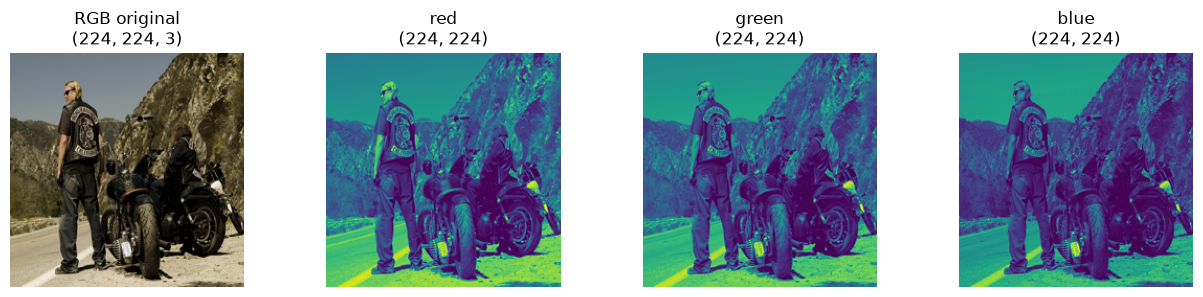

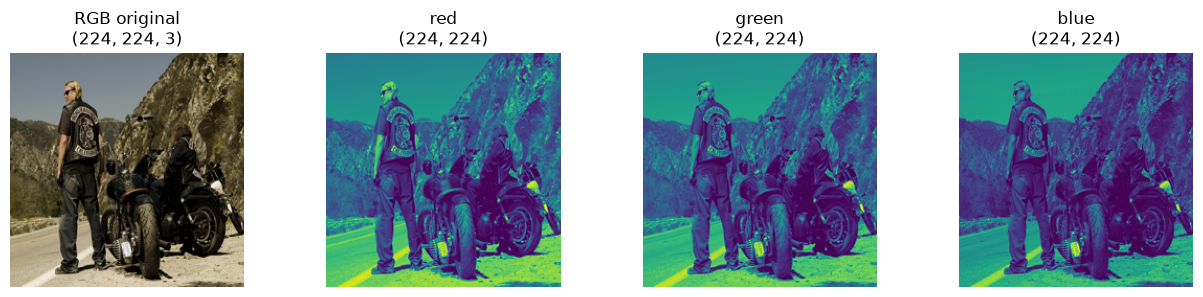

In [9]:
rgb=np.asarray(Image.open(IMAGE_PATH).convert("RGB").resize((224,224)),dtype=np.float32)/255.0; assert rgb.shape==(224,224,3) and np.isfinite(rgb).all()
show_maps([rgb,rgb[...,0],rgb[...,1],rgb[...,2]],["RGB original","red","green","blue"],cols=4,cmap=None)

Random (untrained) Conv2D maps: (1, 224, 224, 8)


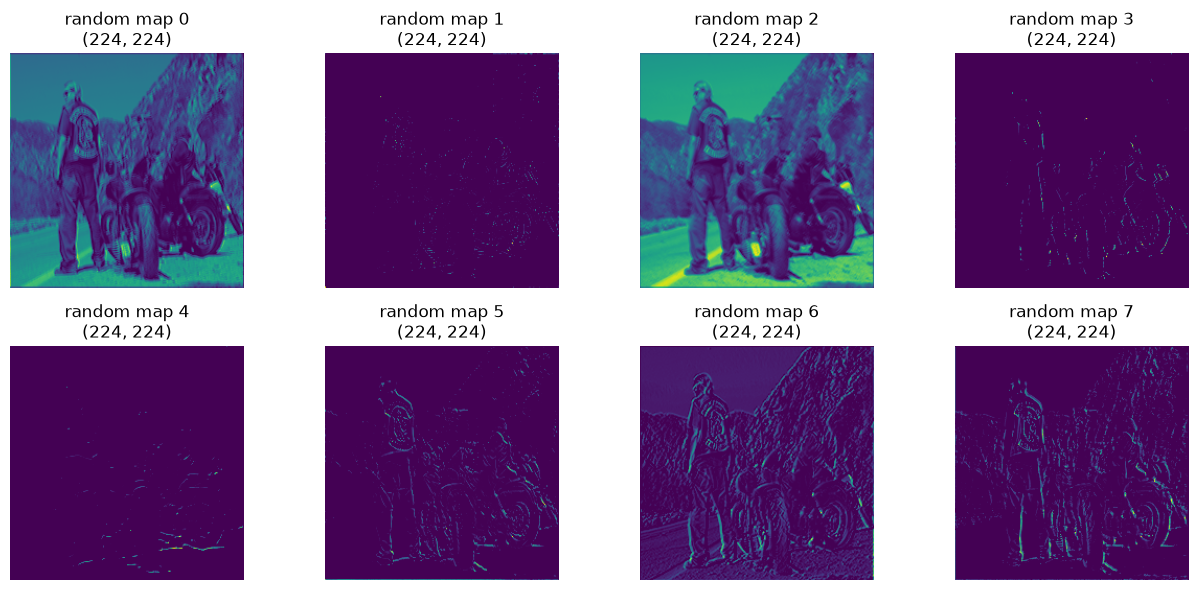

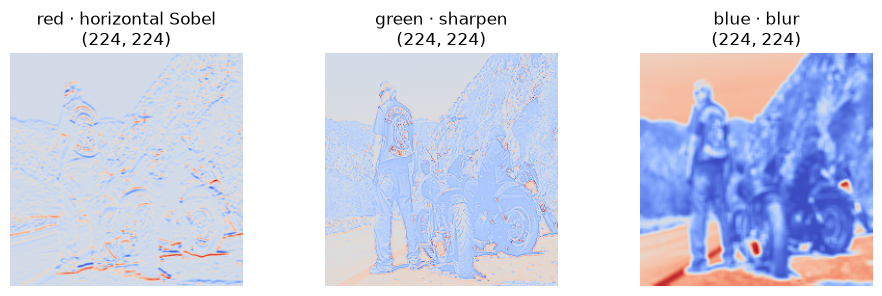

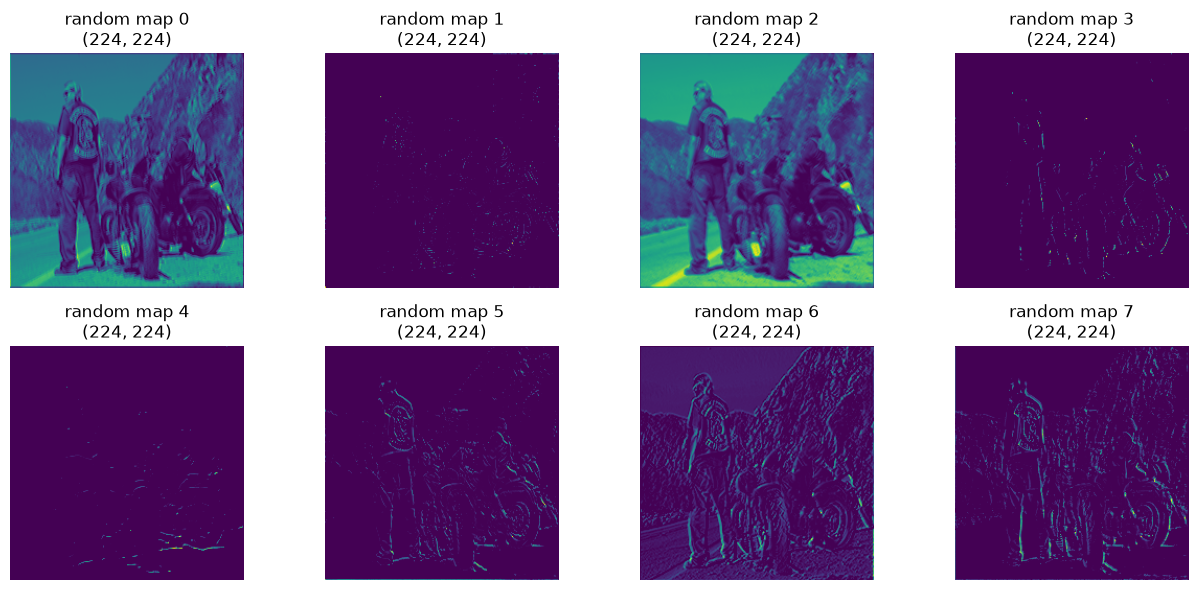

In [10]:
rgb_demo={"red · horizontal Sobel":apply_odd_kernel(rgb[...,0],TISSUE_FILTERS["horizontal Sobel"]),"green · sharpen":apply_odd_kernel(rgb[...,1],np.array([[0,-1,0],[-1,5,-1],[0,-1,0]],np.float32)),"blue · blur":apply_odd_kernel(rgb[...,2],TISSUE_FILTERS["5x5 blur"])}
show_maps(list(rgb_demo.values()),list(rgb_demo),cmap="coolwarm",cols=3)
random_rgb=tf.keras.layers.Conv2D(8,3,padding="same",activation="relu",kernel_initializer=tf.keras.initializers.GlorotUniform(seed=SEED))(rgb[None]); print("Random (untrained) Conv2D maps:",random_rgb.shape)
show_maps([random_rgb[0,...,i] for i in range(8)],[f"random map {i}" for i in range(8)],cols=4)

Loaded MobileNetV2 ImageNet weights: learned pretrained features


block_1_expand_relu (1, 112, 112, 96)
block_6_expand_relu (1, 28, 28, 192)
out_relu (1, 7, 7, 1280)


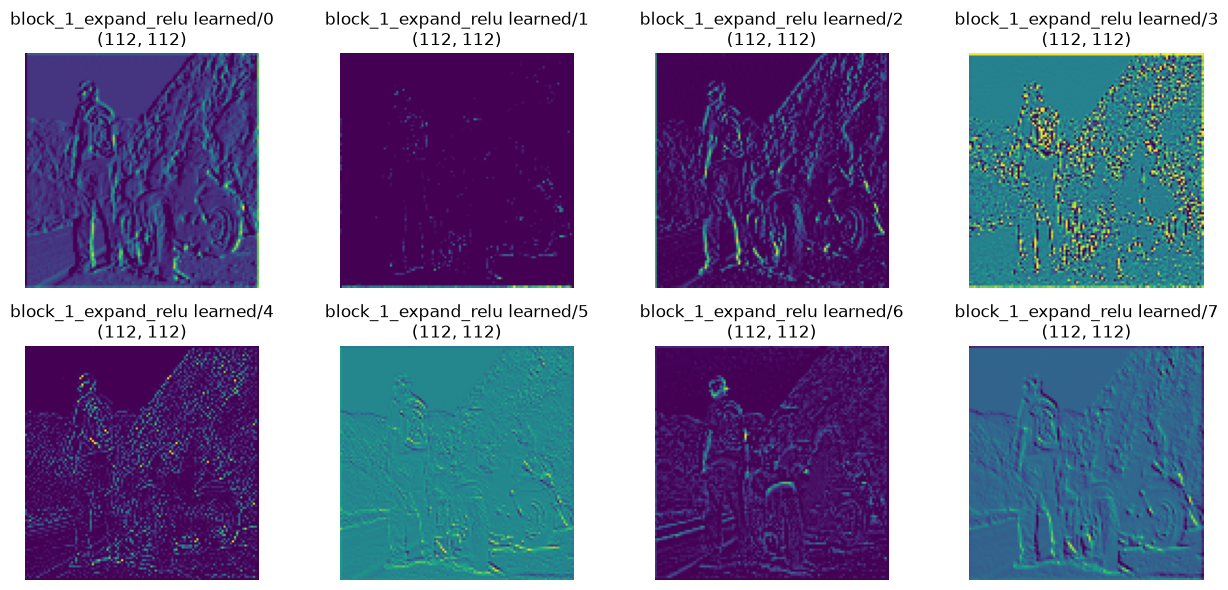

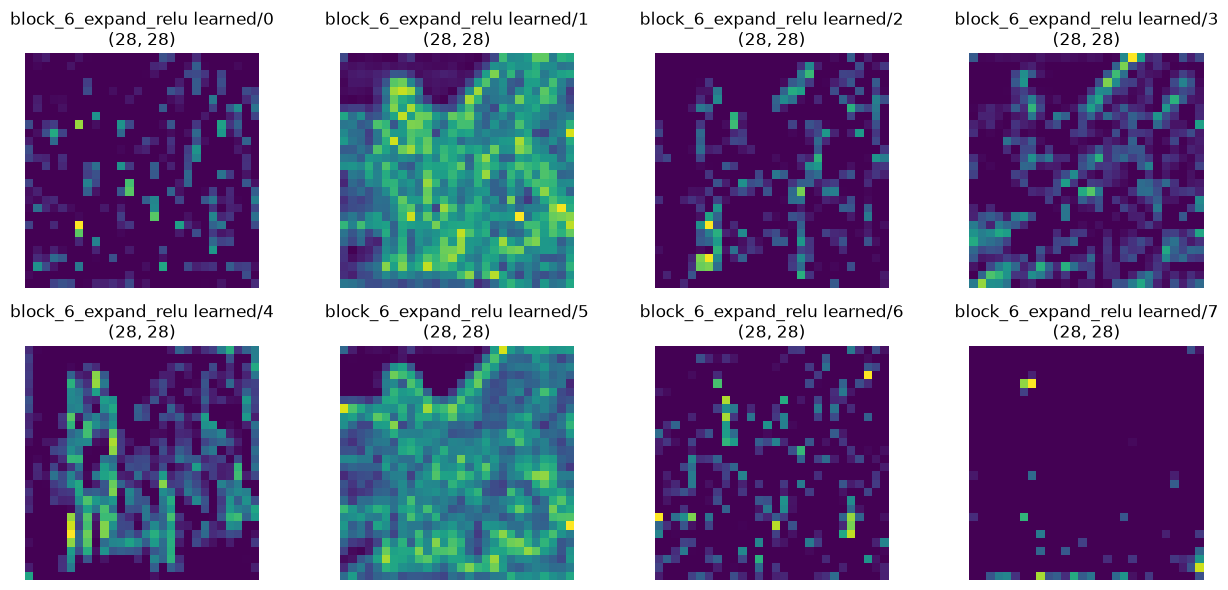

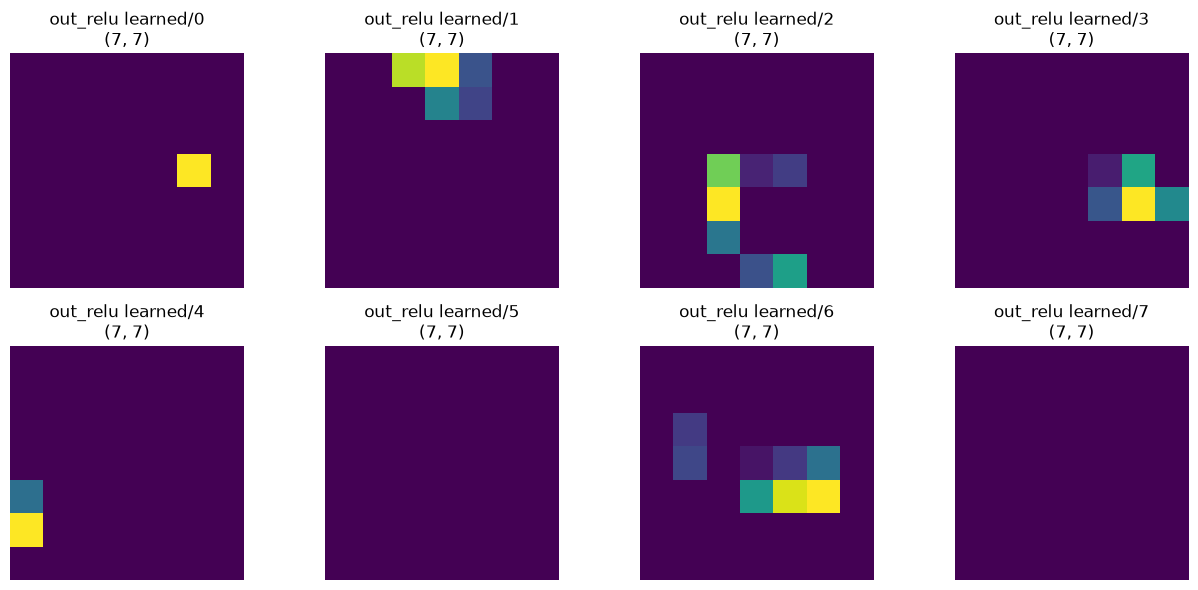

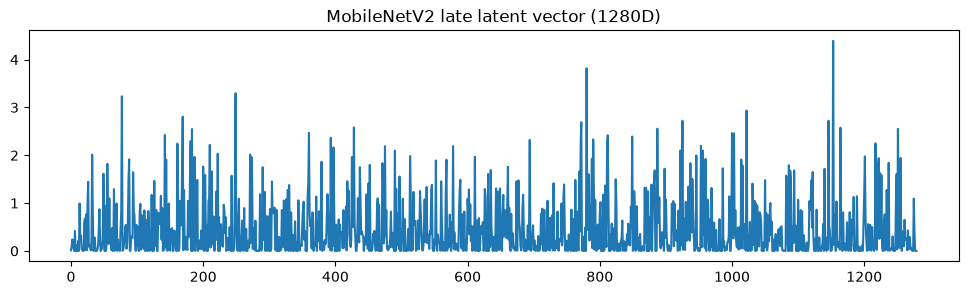

,stage,example_layer,meaning
0,early,block_1_expand_relu,edges/textures
1,mid,block_6_expand_relu,parts/repeated motifs
2,late,out_relu,semantic channels


In [11]:
try:
    mobile=tf.keras.applications.MobileNetV2(include_top=False,weights="imagenet",input_shape=(224,224,3)); mobile.trainable=False; print("Loaded MobileNetV2 ImageNet weights: learned pretrained features")
    mobile_layers=["block_1_expand_relu","block_6_expand_relu","out_relu"]; mobile_probe=tf.keras.Model(mobile.input,[mobile.get_layer(n).output for n in mobile_layers]); mobile_acts=mobile_probe.predict(rgb[None],verbose=0)
    for name,act in zip(mobile_layers,mobile_acts): print(name,act.shape); show_maps([act[0,...,i] for i in range(min(8,act.shape[-1]))],[f"{name} learned/{i}" for i in range(min(8,act.shape[-1]))],cols=4)
    mobile_latent=tf.keras.layers.GlobalAveragePooling2D()(mobile_acts[-1]).numpy()[0]; plt.figure(figsize=(12,3)); plt.plot(mobile_latent); plt.title(f"MobileNetV2 late latent vector ({mobile_latent.shape[0]}D)"); plt.show()
    display(pd.DataFrame({"stage":["early","mid","late"],"example_layer":mobile_layers,"meaning":["edges/textures","parts/repeated motifs","semantic channels"]}))
except Exception as exc:
    print("MobileNetV2 ImageNet feature extraction skipped: pretrained weights/model unavailable in this environment."); print("Fallback detail:",exc)

# Part B — LeNet-5 baseline and bounded tuning

**What:** Preserve classic 32×32 padded-MNIST LeNet-5, search a small bounded KerasTuner space, retrain the winner from fresh weights, and report metrics/activations/latent vector.

**Why:** The baseline anchors the historical architecture; bounded validation-only tuning demonstrates disciplined model selection.

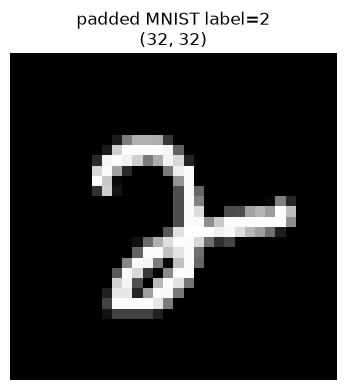

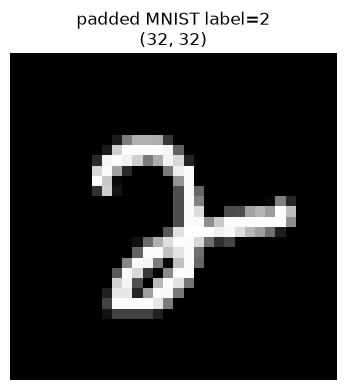

In [12]:
(mnist_train_raw,mnist_y_train_raw),(mnist_test_raw,mnist_y_test)=tf.keras.datasets.mnist.load_data(); mnist_x_train_raw,mnist_x_val_raw,mnist_y_train,mnist_y_val=train_test_split(mnist_train_raw,mnist_y_train_raw,test_size=.1,stratify=mnist_y_train_raw,random_state=SEED)
def prep32(images): return np.pad(images.astype("float32")/255.0,((0,0),(2,2),(2,2)),mode="constant")[...,None]
mnist_x_train,mnist_x_val,mnist_x_test=map(prep32,[mnist_x_train_raw,mnist_x_val_raw,mnist_test_raw]); mnist_y_train,mnist_y_val,mnist_y_test=[x.astype("int64") for x in [mnist_y_train,mnist_y_val,mnist_y_test]]
assert mnist_x_train.shape[1:]==(32,32,1); show_maps([mnist_x_train[0,...,0]],[f"padded MNIST label={mnist_y_train[0]}"],cmap="gray",cols=1,figsize=(4,4))

In [13]:
def build_lenet():
    model=tf.keras.Sequential([tf.keras.layers.Input((32,32,1),name="input"),tf.keras.layers.Conv2D(6,5,activation="tanh",name="conv1"),tf.keras.layers.AveragePooling2D(2,name="pool1"),tf.keras.layers.Conv2D(16,5,activation="tanh",name="conv2"),tf.keras.layers.AveragePooling2D(2,name="pool2"),tf.keras.layers.Conv2D(120,5,activation="tanh",name="conv3"),tf.keras.layers.Flatten(name="flatten"),tf.keras.layers.Dense(84,activation="tanh",name="latent"),tf.keras.layers.Dense(10,activation="softmax",name="classifier")]); model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return model
baseline=build_lenet(); baseline.fit(mnist_x_train,mnist_y_train,validation_data=(mnist_x_val,mnist_y_val),epochs=2,batch_size=128,verbose=2); baseline_eval=baseline.evaluate(mnist_x_test,mnist_y_test,verbose=0); print("LeNet-5 baseline test loss/accuracy:",baseline_eval); display(cnn_complexity(baseline,(32,32,1)))

Epoch 1/2


422/422 - 7s - 16ms/step - accuracy: 0.8972 - loss: 0.3570 - val_accuracy: 0.9458 - val_loss: 0.1791


Epoch 2/2


422/422 - 8s - 18ms/step - accuracy: 0.9599 - loss: 0.1321 - val_accuracy: 0.9652 - val_loss: 0.1181


LeNet-5 baseline test loss/accuracy: [0.10313120484352112, 0.9672999978065491]


,layer,output_shape,parameters,activations,approx_MACs,receptive_field,jump
0,conv1,"(28, 28, 6)",156,4704,117600,5,1
1,pool1,"(14, 14, 6)",0,1176,0,6,2
2,conv2,"(10, 10, 16)",2416,1600,240000,14,2
3,pool2,"(5, 5, 16)",0,400,0,16,4
4,conv3,"(1, 1, 120)",48120,120,48000,32,4
5,flatten,"(120,)",0,120,0,32,4
6,latent,"(84,)",10164,84,10080,32,4
7,classifier,"(10,)",850,10,840,32,4


In [14]:
try:
    import keras_tuner as kt
    def lenet_builder(hp):
        filters=hp.Choice("filters",[6,12]); dense=hp.Choice("dense",[84,120]); lr=hp.Choice("learning_rate",[1e-3,3e-4]); m=tf.keras.Sequential([tf.keras.layers.Input((32,32,1),name="input"),tf.keras.layers.Conv2D(filters,5,activation="tanh",name="conv1"),tf.keras.layers.AveragePooling2D(2,name="pool1"),tf.keras.layers.Conv2D(16,5,activation="tanh",name="conv2"),tf.keras.layers.AveragePooling2D(2,name="pool2"),tf.keras.layers.Conv2D(120,5,activation="tanh",name="conv3"),tf.keras.layers.Flatten(name="flatten"),tf.keras.layers.Dense(dense,activation="tanh",name="latent"),tf.keras.layers.Dense(10,activation="softmax",name="classifier")]); m.compile(optimizer=tf.keras.optimizers.Adam(lr),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
    tuner=kt.RandomSearch(lenet_builder,objective="val_accuracy",max_trials=4,seed=SEED,overwrite=True,directory=str(ROOT/".keras_tuner_unified"),project_name="lenet5"); tuner.search(mnist_x_train,mnist_y_train,validation_data=(mnist_x_val,mnist_y_val),epochs=2,batch_size=128,verbose=0); best_hp=tuner.get_best_hyperparameters(1)[0]; print("Best bounded hyperparameters:",best_hp.values)
    tuned=lenet_builder(best_hp); tuned.fit(mnist_x_train,mnist_y_train,validation_data=(mnist_x_val,mnist_y_val),epochs=3,batch_size=128,verbose=2); tuned_eval=tuned.evaluate(mnist_x_test,mnist_y_test,verbose=0); pred=tuned.predict(mnist_x_test,verbose=0).argmax(1); report=classification_report(mnist_y_test,pred,output_dict=True,zero_division=0); display(pd.DataFrame([{ "model":"baseline","test_accuracy":baseline_eval[1],"parameters":baseline.count_params()},{"model":"tuned fresh retrain","test_accuracy":tuned_eval[1],"parameters":tuned.count_params(),"macro_f1":report["macro avg"]["f1-score"]}])); display(pd.DataFrame(confusion_matrix(mnist_y_test,pred)))
except Exception as exc:
    tuned=None; print("KerasTuner unavailable; bounded tuning skipped with explicit fallback:",exc)

Best bounded hyperparameters: {'filters': 12, 'dense': 84, 'learning_rate': 0.001}
Epoch 1/3


422/422 - 10s - 25ms/step - accuracy: 0.9067 - loss: 0.3237 - val_accuracy: 0.9512 - val_loss: 0.1574


Epoch 2/3


422/422 - 17s - 41ms/step - accuracy: 0.9664 - loss: 0.1089 - val_accuracy: 0.9672 - val_loss: 0.1008


Epoch 3/3


422/422 - 11s - 27ms/step - accuracy: 0.9781 - loss: 0.0724 - val_accuracy: 0.9717 - val_loss: 0.0900


,model,test_accuracy,parameters,macro_f1
0,baseline,0.9673,61706,NaN
1,tuned fresh retrain,0.9778,64262,0.977628


,0,1,2,3,4,5,6,7,8,9
0,969,0,1,0,0,2,3,1,4,0
1,0,1118,4,1,0,0,2,2,8,0
2,2,0,1021,1,1,0,0,5,2,0
3,0,0,8,989,0,0,0,7,6,0
4,0,0,2,0,973,0,3,2,1,1
5,2,0,0,19,0,859,2,1,9,0
6,5,2,2,1,4,1,937,0,6,0
7,1,0,7,4,0,0,0,1015,0,1
8,1,0,7,5,1,1,0,2,956,1
9,3,4,0,9,23,5,0,10,14,941


conv1 (1, 28, 28, 12)
pool1 (1, 14, 14, 12)
conv2 (1, 10, 10, 16)
pool2 (1, 5, 5, 16)
conv3 (1, 1, 1, 120)
flatten (1, 120)
latent (1, 84)
classifier (1, 10)


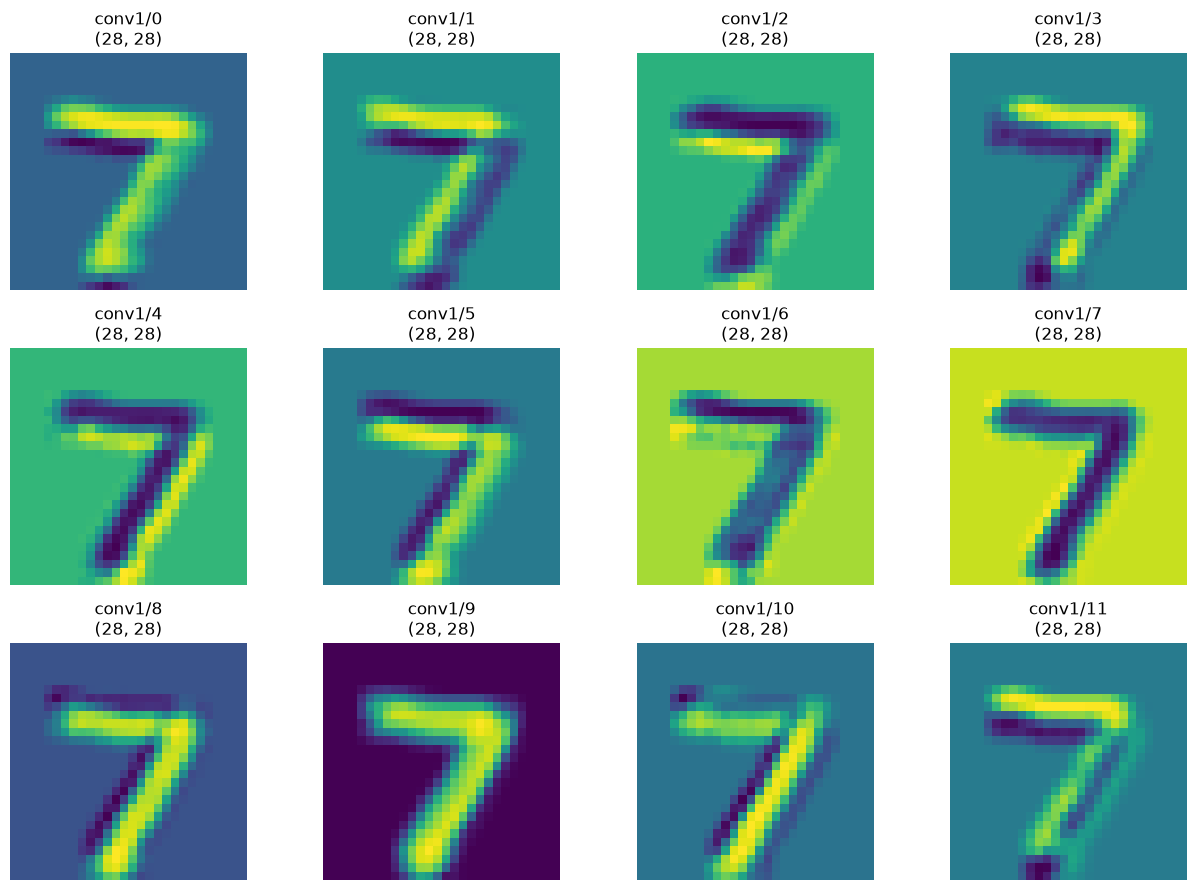

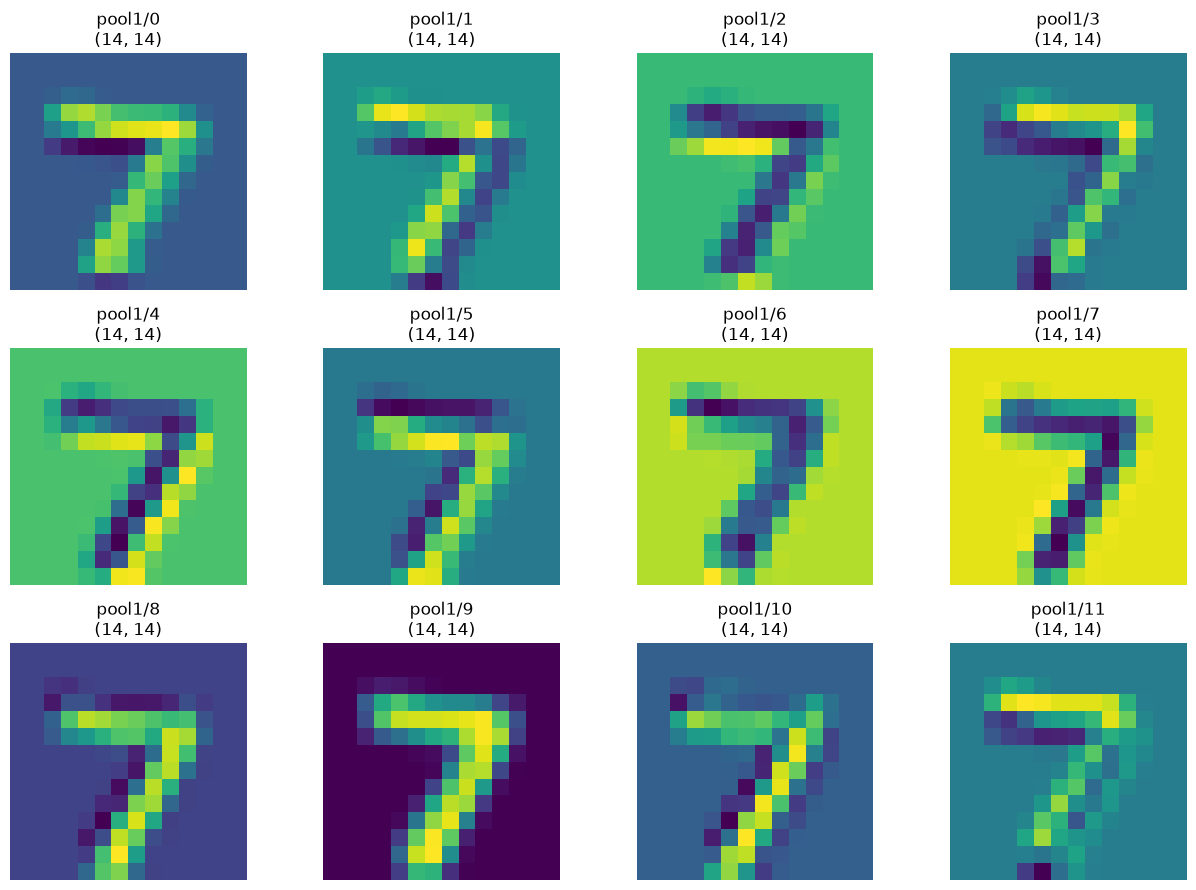

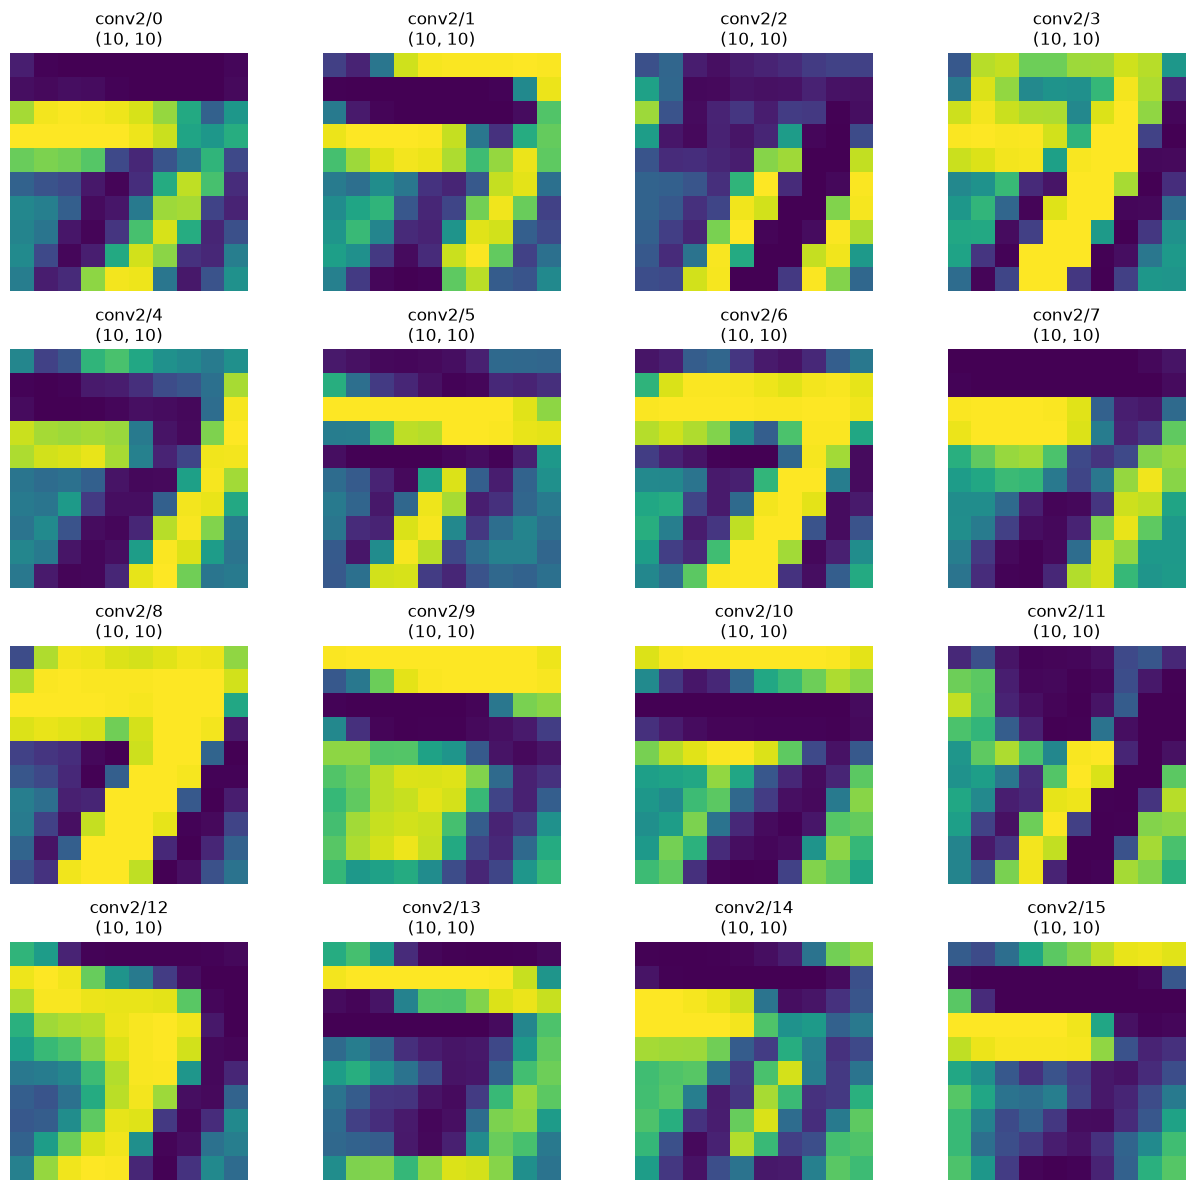

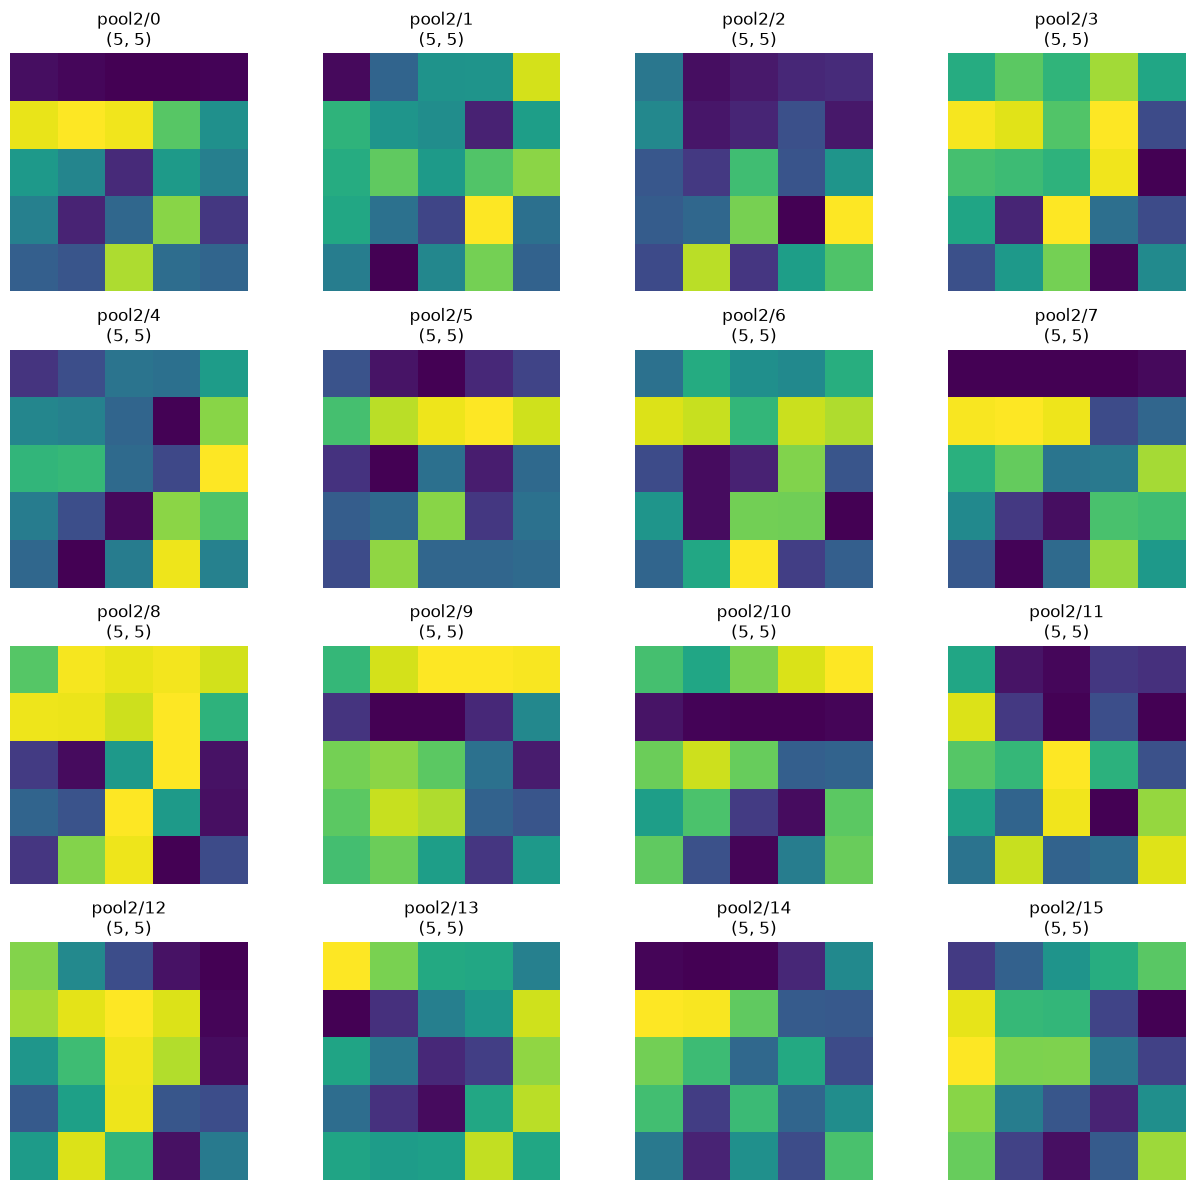

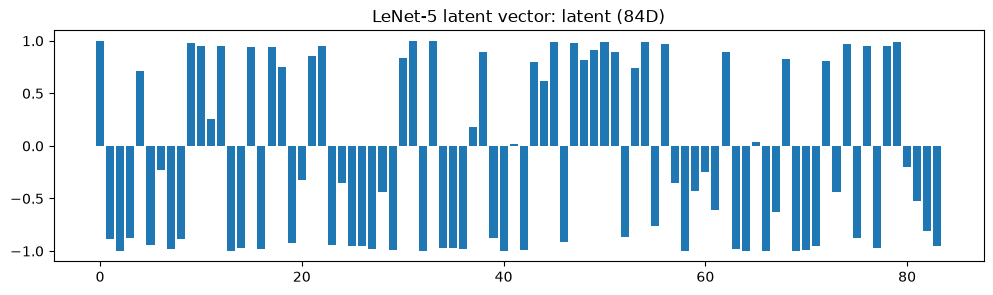

In [15]:
selected=tuned if tuned is not None else baseline; trace_names=[n for n in ["conv1","pool1","conv2","pool2","conv3","flatten","latent","classifier"] if any(l.name==n for l in selected.layers)]; trace_model=tf.keras.Model(selected.inputs[0],[selected.get_layer(n).output for n in trace_names]); trace_acts=dict(zip(trace_names,trace_model.predict(mnist_x_test[:1],verbose=0)))
for n,a in trace_acts.items(): print(n,a.shape)
for n in ["conv1","pool1","conv2","pool2"]:
    a=trace_acts[n][0]; show_maps([a[...,i] for i in range(min(a.shape[-1],16))],[f"{n}/{i}" for i in range(min(a.shape[-1],16))],cols=4)
latent_name="latent" if "latent" in trace_acts else "flatten"; plt.figure(figsize=(12,3)); plt.bar(np.arange(trace_acts[latent_name].shape[-1]),trace_acts[latent_name][0]); plt.title(f"LeNet-5 latent vector: {latent_name} ({trace_acts[latent_name].shape[-1]}D)"); plt.show(); assert trace_acts["classifier"].shape==(1,10)

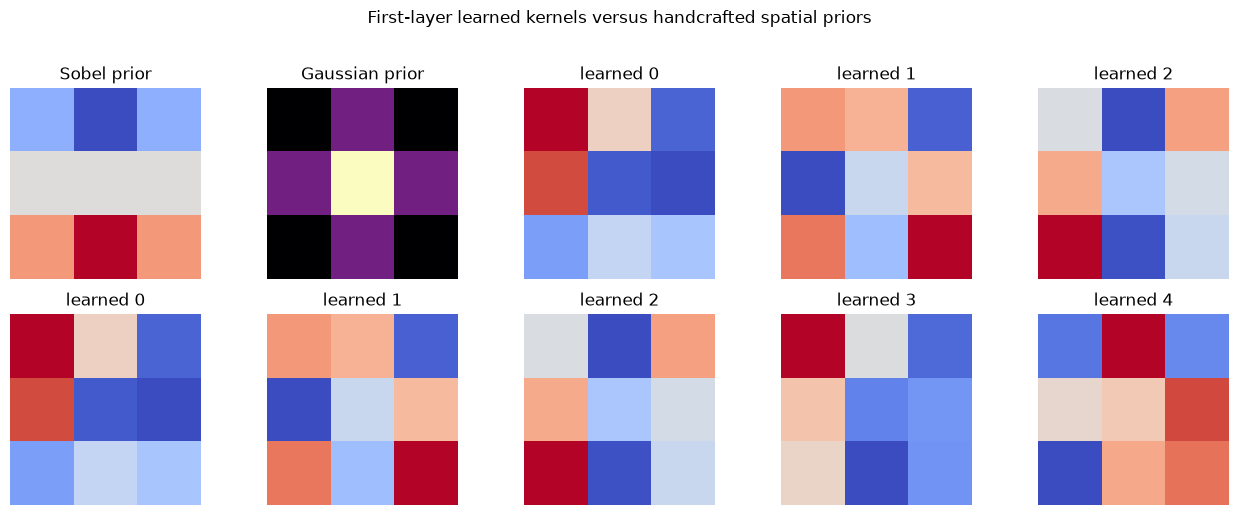

In [16]:
# Publication-grade learned-vs-handcrafted kernel comparison.
if tissue_available and "tissue_model" in globals():
    tissue_conv1_layer = tissue_model.get_layer("tissue_conv1")
    tissue_conv1_kernels = tissue_conv1_layer.get_weights()[0]
    sobel_kernel = TISSUE_FILTERS["horizontal Sobel"]
    gaussian_kernel = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32) / 16.0
    fig, axes = plt.subplots(2, 5, figsize=(13, 5))
    axes[0, 0].imshow(sobel_kernel, cmap="coolwarm"); axes[0, 0].set_title("Sobel prior")
    axes[0, 1].imshow(gaussian_kernel, cmap="magma"); axes[0, 1].set_title("Gaussian prior")
    for ax, idx in zip(axes[0, 2:], range(min(3, tissue_conv1_kernels.shape[-1]))):
        ax.imshow(tissue_conv1_kernels[..., 0, idx], cmap="coolwarm")
        ax.set_title(f"learned {idx}")
    for ax, idx in zip(axes[1], range(min(5, tissue_conv1_kernels.shape[-1]))):
        ax.imshow(tissue_conv1_kernels[..., 0, idx], cmap="coolwarm")
        ax.set_title(f"learned {idx}")
    for ax in axes.ravel(): ax.axis("off")
    fig.suptitle("First-layer learned kernels versus handcrafted spatial priors", y=1.02)
    plt.tight_layout(); plt.show()
else:
    print("Learned TissueMNIST kernels skipped: tissue model is unavailable.")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6798442..1.0].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.8492144].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.99999994..0.84738916].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-7.488176e-13..1.0159872e-13].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.80887115].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.151926].


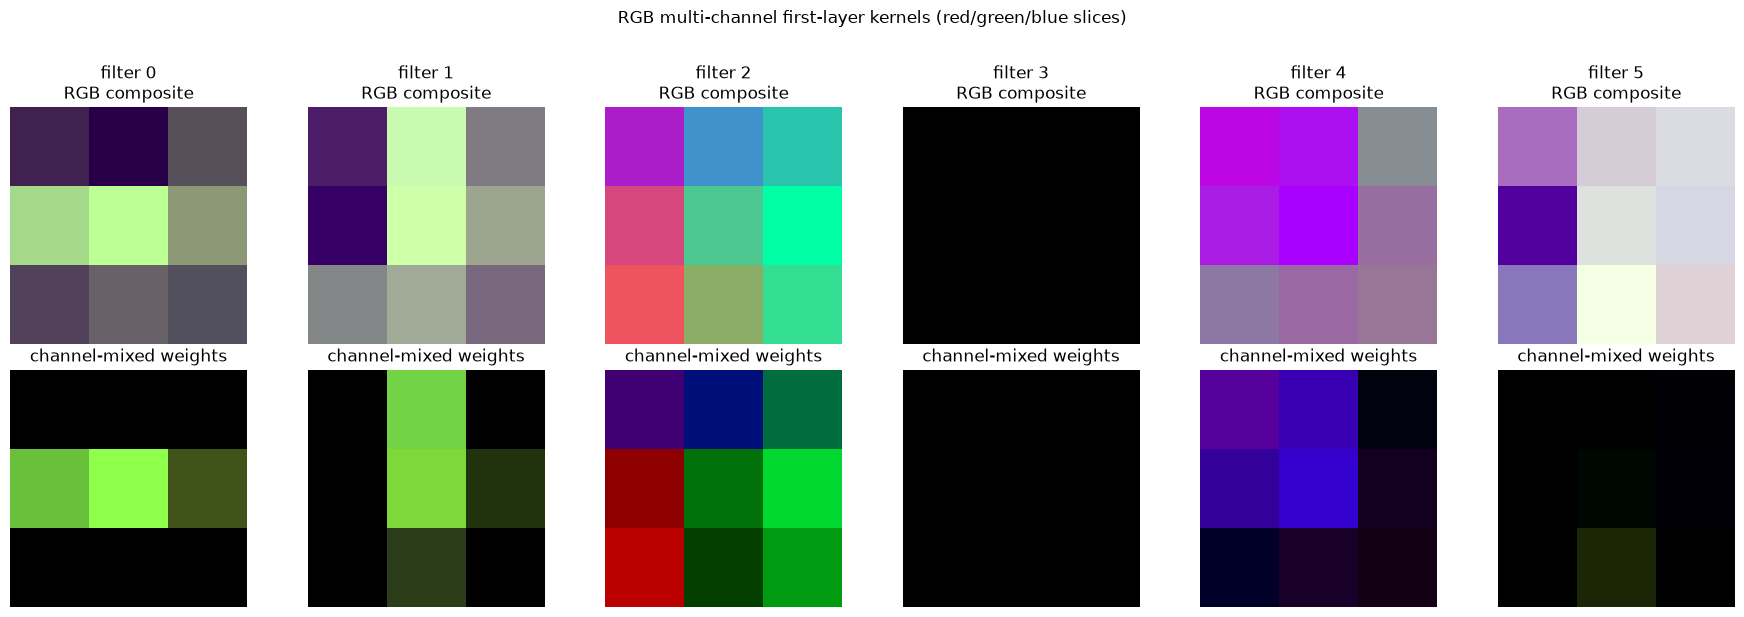

In [17]:
# RGB kernels have one 2-D slice per input channel; the slices are summed to form each output map.
rgb_kernel_model = None
if "mobile" in globals():
    rgb_kernel_candidates = [layer for layer in mobile.layers if isinstance(layer, tf.keras.layers.Conv2D) and layer.input.shape[-1] == 3]
    if rgb_kernel_candidates:
        rgb_kernel_model = rgb_kernel_candidates[0]
if rgb_kernel_model is None:
    rgb_kernel_model = tf.keras.layers.Conv2D(8, 3, padding="same", use_bias=False, name="rgb_kernel_demo")
    _ = rgb_kernel_model(rgb[None])
rgb_kernels = rgb_kernel_model.get_weights()[0]
rgb_plot_count = min(6, rgb_kernels.shape[-1])
fig, axes = plt.subplots(2, rgb_plot_count, figsize=(3.0 * rgb_plot_count, 6), squeeze=False)
for idx in range(rgb_plot_count):
    kernel_rgb = rgb_kernels[..., idx]
    scale = np.max(np.abs(kernel_rgb)) + 1e-8
    axes[0, idx].imshow((kernel_rgb - kernel_rgb.min()) / (kernel_rgb.max() - kernel_rgb.min() + 1e-8))
    axes[0, idx].set_title(f"filter {idx}\nRGB composite")
    axes[1, idx].imshow(kernel_rgb / scale, cmap="coolwarm", vmin=-1, vmax=1)
    axes[1, idx].set_title("channel-mixed weights")
    axes[0, idx].axis("off"); axes[1, idx].axis("off")
fig.suptitle("RGB multi-channel first-layer kernels (red/green/blue slices)", y=1.02)
plt.tight_layout(); plt.show()

### Lightweight Grad-CAM

Grad-CAM weights each feature map by the mean gradient of the chosen class score. This is intentionally a single-image, single-layer diagnostic rather than a full interpretability framework; it is skipped cleanly when the optional TissueMNIST model is not available.

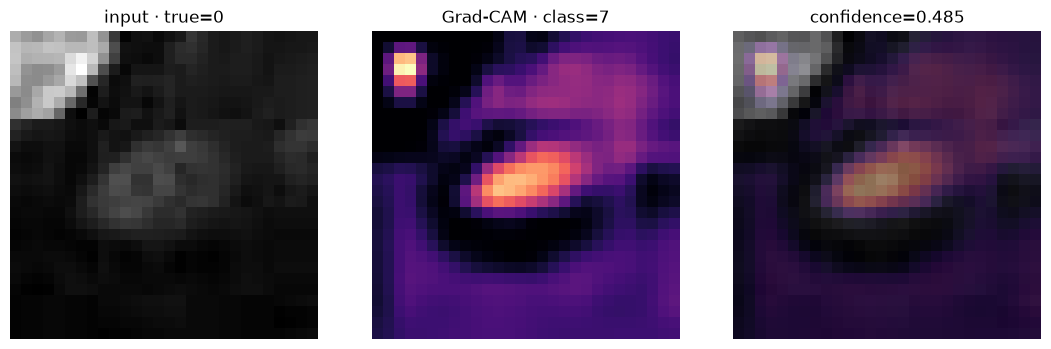

In [18]:
def lightweight_gradcam(model, image_batch, layer_name=None, class_index=None):
    conv_layers = [layer for layer in model.layers if isinstance(layer, tf.keras.layers.Conv2D)]
    if not conv_layers: return None, None, None
    target_layer = model.get_layer(layer_name) if layer_name else conv_layers[-1]
    grad_model = tf.keras.Model(model.inputs[0], [target_layer.output, model.layers[-1].output])
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(image_batch, training=False)
        chosen = tf.argmax(predictions[0]) if class_index is None else tf.constant(class_index)
        score = predictions[:, chosen]
    gradients = tape.gradient(score, conv_output)
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    cam = tf.reduce_sum(weights * conv_output, axis=-1)[0]
    cam = tf.maximum(cam, 0)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(chosen), predictions[0].numpy()

if tissue_available and "tissue_model" in globals():
    gradcam_image = tissue_test[:1]
    gradcam_map, gradcam_class, gradcam_probs = lightweight_gradcam(tissue_model, gradcam_image, "tissue_conv2")
    gradcam_resized = tf.image.resize(gradcam_map[..., None], gradcam_image.shape[1:3]).numpy()[..., 0]
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))
    ax[0].imshow(gradcam_image[0, ..., 0], cmap="gray"); ax[0].set_title(f"input · true={tissue_y_test[0]}"); ax[0].axis("off")
    ax[1].imshow(gradcam_resized, cmap="magma"); ax[1].set_title(f"Grad-CAM · class={gradcam_class}"); ax[1].axis("off")
    ax[2].imshow(gradcam_image[0, ..., 0], cmap="gray"); ax[2].imshow(gradcam_resized, cmap="magma", alpha=.45); ax[2].set_title(f"confidence={gradcam_probs[gradcam_class]:.3f}"); ax[2].axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Grad-CAM skipped: no trained TissueMNIST model is available.")

## Latent-space clustering on 500 MNIST samples

The plotted points are the selected LeNet representation (the tuned model when available, otherwise the baseline). PCA is deterministic and cheap; t-SNE is capped at 500 samples and 500 iterations so this remains a lightweight exploratory analysis.

/private/tmp/ipykernel_38016/1968908253.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


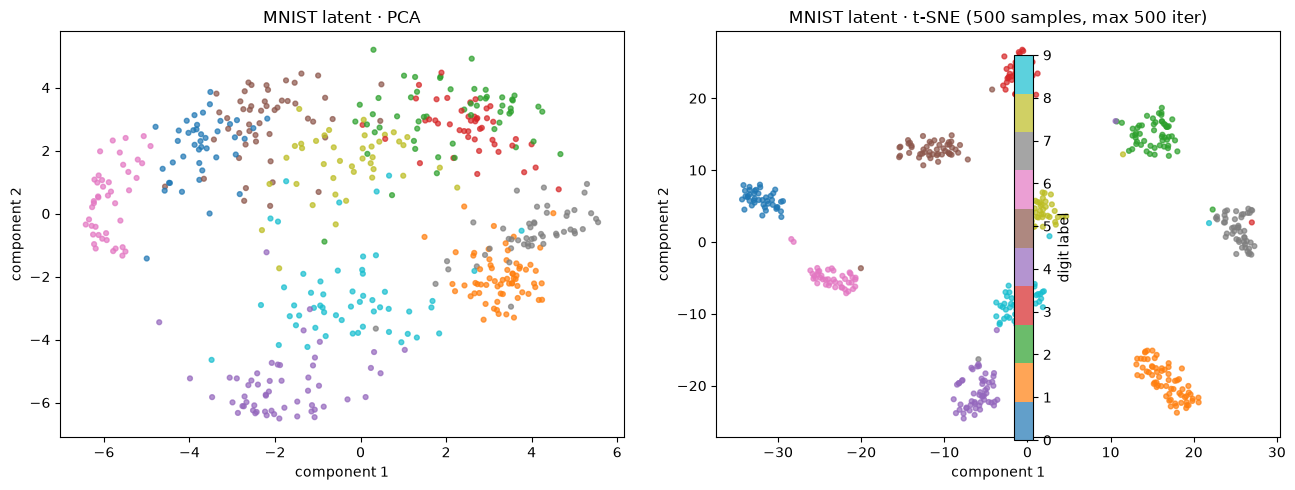

In [19]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

if "selected" in globals() and "mnist_x_test" in globals():
    cluster_count = min(500, len(mnist_x_test))
    cluster_images = mnist_x_test[:cluster_count]
    cluster_labels = mnist_y_test[:cluster_count]
    cluster_layer_name = "latent" if any(layer.name == "latent" for layer in selected.layers) else "flatten"
    cluster_encoder = tf.keras.Model(selected.inputs, selected.get_layer(cluster_layer_name).output)
    cluster_vectors = cluster_encoder.predict(cluster_images, batch_size=128, verbose=0)
    cluster_vectors = np.asarray(cluster_vectors).reshape(cluster_count, -1)
    cluster_pca = PCA(n_components=2, random_state=SEED).fit_transform(cluster_vectors)
    cluster_tsne = TSNE(n_components=2, perplexity=min(30, max(5, cluster_count // 20)), init="pca", learning_rate="auto", max_iter=500, random_state=SEED).fit_transform(cluster_vectors)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, coords, title in zip(axes, [cluster_pca, cluster_tsne], ["PCA", "t-SNE (500 samples, max 500 iter)"]):
        scatter = ax.scatter(coords[:, 0], coords[:, 1], c=cluster_labels, cmap="tab10", s=12, alpha=.7)
        ax.set_title(f"MNIST {cluster_layer_name} · {title}"); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    fig.colorbar(scatter, ax=axes.ravel().tolist(), ticks=range(10), label="digit label")
    plt.tight_layout(); plt.show()
else:
    print("Latent clustering skipped: MNIST model or test data is unavailable.")

## Per-class metrics and highest-confidence mistakes

Precision, recall, and F1 are reported for every digit rather than only as a macro average. The image grid ranks errors by the model's confidence in its incorrect prediction, which makes visually plausible but systematically confusing cases easy to inspect.

,precision,recall,F1,support
class,,,,
0,0.986,0.989,0.987,980
1,0.995,0.985,0.990,1135
2,0.971,0.989,0.980,1032
3,0.961,0.979,0.970,1010
4,0.971,0.991,0.981,982
5,0.990,0.963,0.976,892
6,0.989,0.978,0.984,958
7,0.971,0.987,0.979,1028
8,0.950,0.982,0.966,974


,sample_index,true,predicted,confidence
0,9587,9,4,0.999
1,4880,0,8,0.997
2,2995,6,8,0.996
3,3767,7,2,0.996
4,4224,9,7,0.993
5,4271,5,3,0.991
6,1226,7,2,0.990
7,5937,5,3,0.988
8,3869,9,4,0.987
9,5955,3,8,0.987


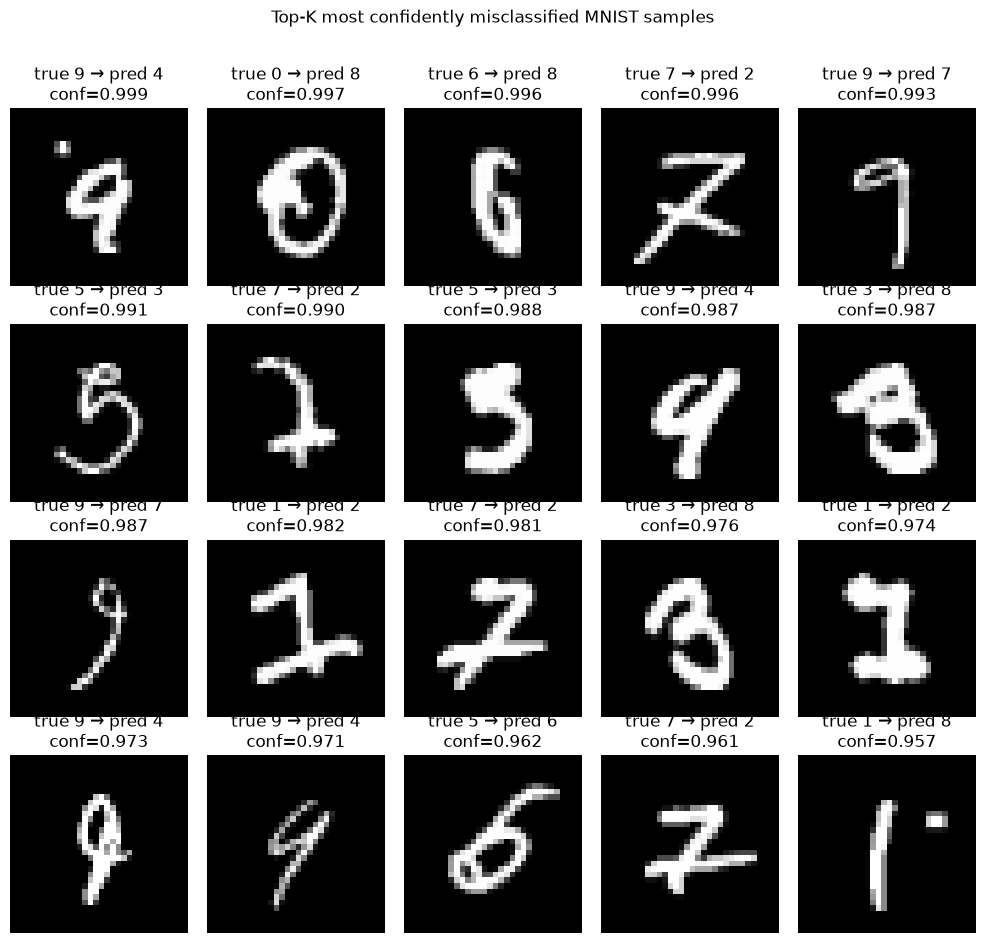

In [20]:
from sklearn.metrics import precision_recall_fscore_support

if "selected" in globals() and "mnist_x_test" in globals():
    analysis_probs = selected.predict(mnist_x_test, batch_size=256, verbose=0)
    analysis_pred = analysis_probs.argmax(axis=1)
    analysis_conf = analysis_probs.max(axis=1)
    analysis_precision, analysis_recall, analysis_f1, analysis_support = precision_recall_fscore_support(mnist_y_test, analysis_pred, labels=np.arange(10), zero_division=0)
    metrics_df = pd.DataFrame({"class": np.arange(10), "precision": analysis_precision, "recall": analysis_recall, "F1": analysis_f1, "support": analysis_support}).set_index("class")
    display(metrics_df.style.format({"precision":"{:.3f}", "recall":"{:.3f}", "F1":"{:.3f}"}).background_gradient(cmap="Blues", subset=["precision", "recall", "F1"]))
    misclassified = np.flatnonzero(analysis_pred != mnist_y_test)
    ranked_errors = misclassified[np.argsort(analysis_conf[misclassified])[::-1]]
    top_k_errors = ranked_errors[:min(20, len(ranked_errors))]
    error_table = pd.DataFrame({"sample_index": top_k_errors, "true": mnist_y_test[top_k_errors], "predicted": analysis_pred[top_k_errors], "confidence": analysis_conf[top_k_errors]})
    display(error_table.style.format({"confidence":"{:.3f}"}))
    error_cols = 5; error_rows = int(np.ceil(len(top_k_errors) / error_cols))
    fig, axes = plt.subplots(error_rows, error_cols, figsize=(10, 2.3 * error_rows), squeeze=False)
    for ax, idx in zip(axes.ravel(), top_k_errors):
        ax.imshow(mnist_x_test[idx, ..., 0], cmap="gray")
        ax.set_title(f"true {mnist_y_test[idx]} → pred {analysis_pred[idx]}\nconf={analysis_conf[idx]:.3f}")
        ax.axis("off")
    for ax in axes.ravel()[len(top_k_errors):]: ax.axis("off")
    fig.suptitle("Top-K most confidently misclassified MNIST samples", y=1.02)
    plt.tight_layout(); plt.show()
else:
    print("Per-class metrics and error grid skipped: MNIST model or test data is unavailable.")

## Parameter versus MAC efficiency

Approximate MACs count multiply-accumulate work for spatial convolutions as $H_oW_oC_o(k_hk_wC_i)$, depthwise convolutions as $H_oW_oC_i(k_hk_w)$, and dense layers as $C_iC_o$. Bias adds, activation functions, pooling, batch normalization, and framework overhead are intentionally excluded. Therefore this is a comparable order-of-magnitude proxy, not a hardware benchmark.

,model,parameters,approx_MACs
0,Tissue CNN,26632,307584
1,LeNet-5,61706,416520
2,MobileNetV2,2257984,299494272


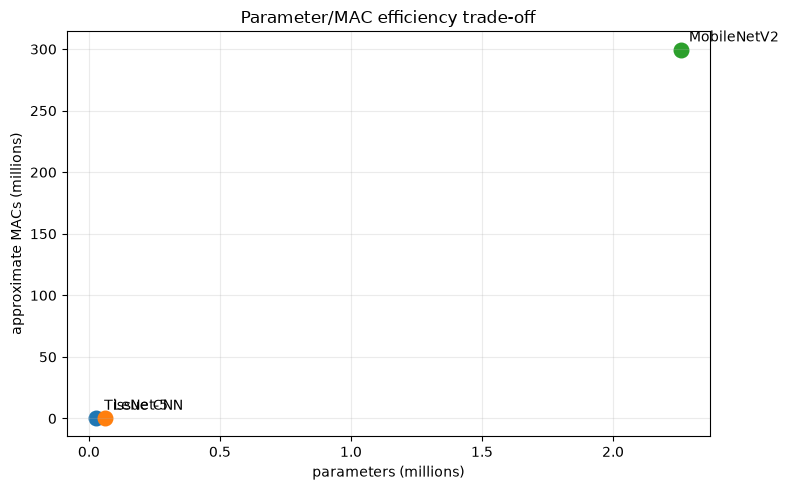

In [21]:
def approximate_layer_macs(model):
    rows = []
    for layer in model.layers:
        macs = 0
        try:
            output_shape = tuple(int(v) for v in layer.output.shape[1:] if v is not None)
            input_channels = int(layer.input.shape[-1]) if hasattr(layer, "input") and layer.input.shape[-1] is not None else 0
            if isinstance(layer, tf.keras.layers.Conv2D):
                kh, kw = layer.kernel_size
                macs = int(np.prod(output_shape[:2]) * output_shape[-1] * kh * kw * input_channels)
            elif isinstance(layer, tf.keras.layers.DepthwiseConv2D):
                kh, kw = layer.kernel_size
                macs = int(np.prod(output_shape[:2]) * output_shape[-1] * kh * kw)
            elif isinstance(layer, tf.keras.layers.Dense):
                macs = int(layer.input.shape[-1]) * layer.units
        except (TypeError, ValueError, AttributeError, IndexError):
            pass
        rows.append({"layer": layer.name, "parameters": layer.count_params(), "approx_MACs": macs})
    return pd.DataFrame(rows)

efficiency_models = {}
if tissue_available and "tissue_model" in globals(): efficiency_models["Tissue CNN"] = (tissue_model, tissue_train.shape[1:])
if "baseline" in globals(): efficiency_models["LeNet-5"] = (baseline, (32, 32, 1))
if "mobile" in globals(): efficiency_models["MobileNetV2"] = (mobile, (224, 224, 3))
if efficiency_models:
    efficiency_rows = []
    for efficiency_name, (efficiency_model, efficiency_shape) in efficiency_models.items():
        efficiency_detail = approximate_layer_macs(efficiency_model)
        efficiency_rows.append({"model": efficiency_name, "parameters": efficiency_model.count_params(), "approx_MACs": int(efficiency_detail["approx_MACs"].sum())})
    efficiency_df = pd.DataFrame(efficiency_rows)
    display(efficiency_df)
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, row in efficiency_df.iterrows():
        ax.scatter(row["parameters"] / 1e6, row["approx_MACs"] / 1e6, s=110)
        ax.annotate(row["model"], (row["parameters"] / 1e6, row["approx_MACs"] / 1e6), xytext=(6, 6), textcoords="offset points")
    ax.set_xlabel("parameters (millions)"); ax.set_ylabel("approximate MACs (millions)"); ax.set_title("Parameter/MAC efficiency trade-off")
    ax.grid(alpha=.25); plt.tight_layout(); plt.show()
else:
    print("Efficiency plot skipped: no compatible models are available.")

# Final learning and rubric/critique

**What:** Summarize transferable lessons and audit the notebook against the requested evidence.

**Why:** A critique table makes omissions visible instead of treating plots as proof by themselves.

### Additional learning

1. Correlation and true convolution differ by the spatial kernel flip; this matters when interpreting edge direction.
2. Pooling reduces spatial cost while increasing effective receptive field; later maps trade localization for abstraction.
3. Random kernels are not learned features: training aligns weights with labels.
4. RGB filters have one spatial slice per input channel and sum channel contributions into each output map.
5. A latent vector is a compact representation, not a class-probability vector.
6. Test metrics should be reported after model selection and fresh retraining.

In [22]:
rubric=pd.DataFrame([{"requirement":"A1 TissueMNIST grayscale + preprocessing + original image","evidence":"medmnist load, normalization assertions, original image plot"},{"requirement":"Odd-kernel helper + filters + correlation vs true convolution","evidence":"apply_odd_kernel, true_convolution, Sobel/blur/Laplacian plots"},{"requirement":"Built-in Conv2D comparison + trained CNN + traces","evidence":"fixed Conv2D error check; Tissue CNN activations/latent/complexity"},{"requirement":"A2 RGB image + custom filter demo","evidence":"relative sons_of_anarchy.jpg path; channel/custom-filter maps"},{"requirement":"MobileNetV2 early/mid/late + latent + fallback","evidence":"ImageNet load guarded; three probe stages and vector"},{"requirement":"Part B LeNet baseline + bounded tuning + fresh retrain","evidence":"classic model, max_trials=4, rebuilt tuned model, test report"},{"requirement":"Final learning and critique","evidence":"additional-learning text and this table"}]); display(rubric); print("Unified notebook checks complete.")

,requirement,evidence
0,A1 TissueMNIST grayscale + preprocessing + ori...,"medmnist load, normalization assertions, origi..."
1,Odd-kernel helper + filters + correlation vs t...,"apply_odd_kernel, true_convolution, Sobel/blur..."
2,Built-in Conv2D comparison + trained CNN + traces,fixed Conv2D error check; Tissue CNN activatio...
3,A2 RGB image + custom filter demo,relative sons_of_anarchy.jpg path; channel/cus...
4,MobileNetV2 early/mid/late + latent + fallback,ImageNet load guarded; three probe stages and ...
5,Part B LeNet baseline + bounded tuning + fresh...,"classic model, max_trials=4, rebuilt tuned mod..."
6,Final learning and critique,additional-learning text and this table


Unified notebook checks complete.


## A1.1 Filter gallery, kernel sizes, and border padding

**What:** Compare several hand-designed kernels, kernel sizes, and padding conventions on the same TissueMNIST image.

**Why:** Kernel weights determine the pattern being detected, while padding changes border evidence and output dimensions.


Kernel shapes and roles:


,kernel,shape
0,3x3 horizontal Sobel,"(3, 3)"
1,3x3 vertical Sobel,"(3, 3)"
2,3x3 Laplacian,"(3, 3)"
3,3x3 sharpen,"(3, 3)"
4,3x3 emboss,"(3, 3)"
5,3x3 box blur,"(3, 3)"
6,5x5 Gaussian-like,"(5, 5)"


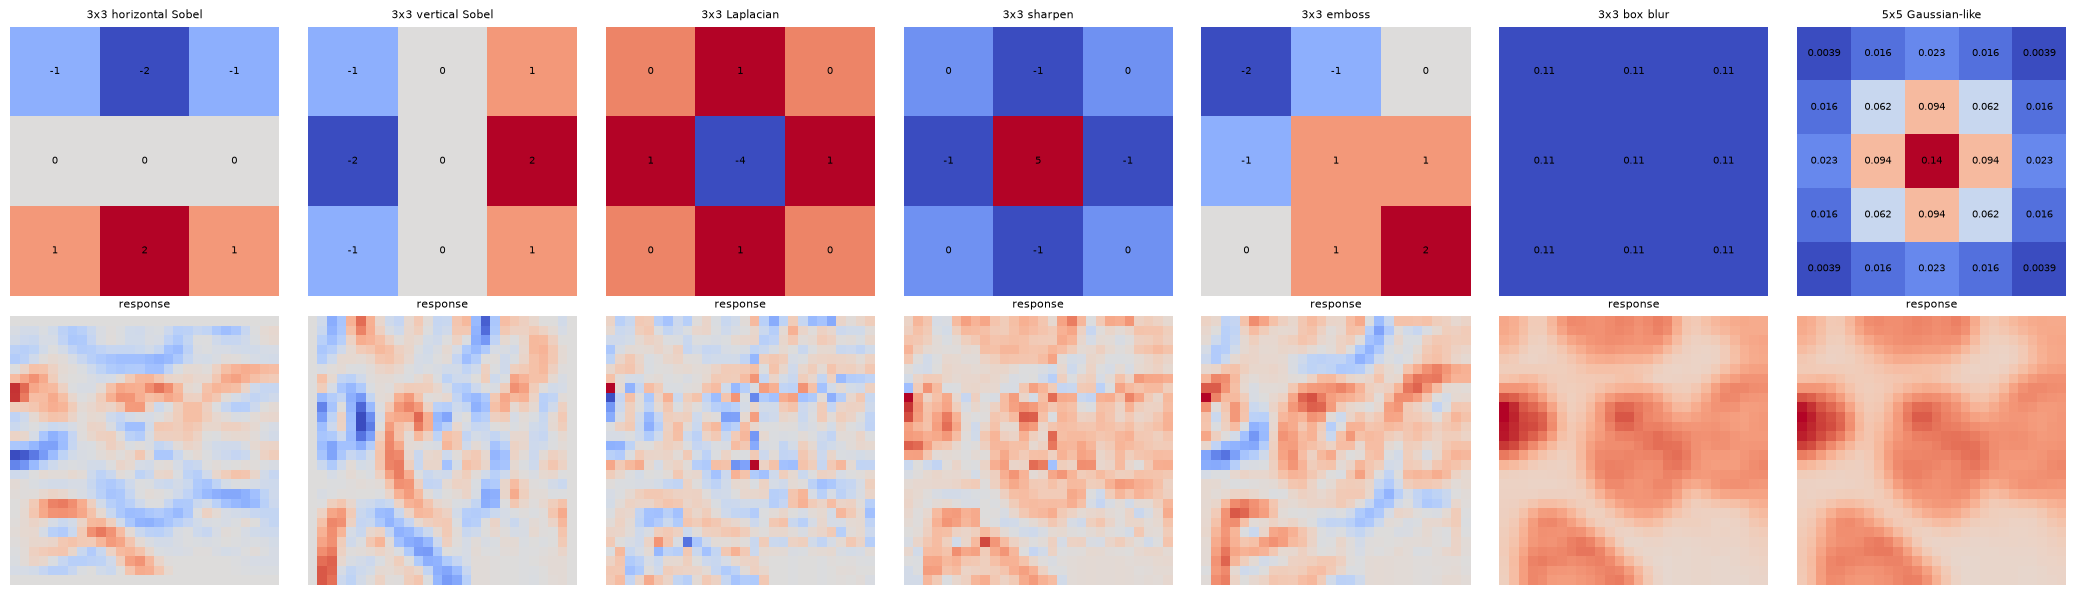

Padding shapes: {'constant': (28, 28), 'reflect': (28, 28), 'edge': (28, 28)} Keras valid: (26, 26) Keras same: (28, 28)


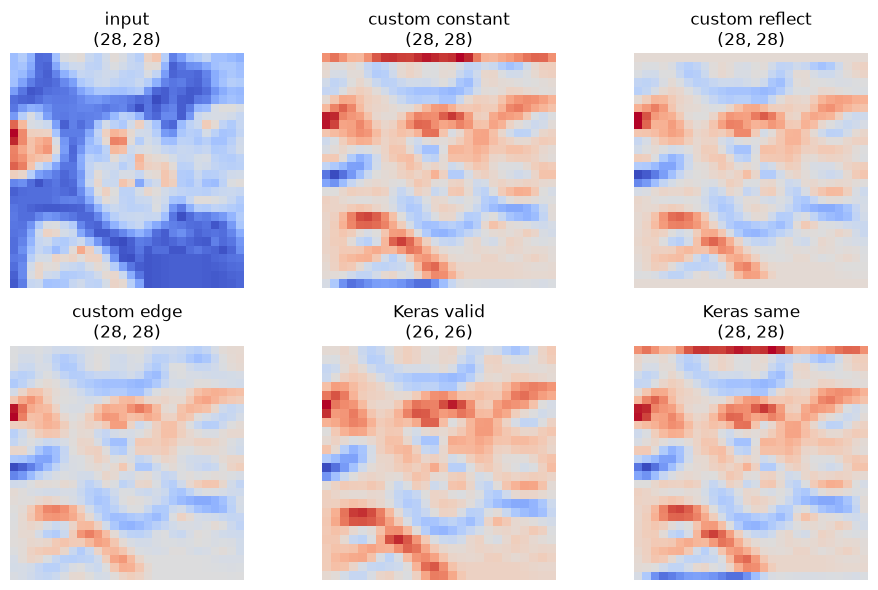

In [23]:
if tissue_available:
    filter_gallery = {
        "3x3 horizontal Sobel": np.array([[-1,-2,-1],[0,0,0],[1,2,1]], np.float32),
        "3x3 vertical Sobel": np.array([[-1,0,1],[-2,0,2],[-1,0,1]], np.float32),
        "3x3 Laplacian": np.array([[0,1,0],[1,-4,1],[0,1,0]], np.float32),
        "3x3 sharpen": np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], np.float32),
        "3x3 emboss": np.array([[-2,-1,0],[-1,1,1],[0,1,2]], np.float32),
        "3x3 box blur": np.ones((3,3), np.float32)/9,
        "5x5 Gaussian-like": np.array([[1,4,6,4,1],[4,16,24,16,4],[6,24,36,24,6],[4,16,24,16,4],[1,4,6,4,1]], np.float32)/256,
    }
    print("Kernel shapes and roles:")
    display(pd.DataFrame({"kernel": list(filter_gallery), "shape": [v.shape for v in filter_gallery.values()]}))
    # Display annotated weights and responses without hiding the actual numerical filters.
    fig, axes = plt.subplots(2, len(filter_gallery), figsize=(3*len(filter_gallery), 6))
    for col, (name, kernel) in enumerate(filter_gallery.items()):
        axes[0,col].imshow(kernel, cmap="coolwarm", interpolation="nearest")
        axes[0,col].set_title(name, fontsize=8)
        for r in range(kernel.shape[0]):
            for c in range(kernel.shape[1]): axes[0,col].text(c,r,f"{kernel[r,c]:.2g}",ha="center",va="center",fontsize=7)
        axes[0,col].axis("off")
        response=apply_odd_kernel(sample_gray,kernel)
        scale=max(abs(response.min()),abs(response.max()),1e-6)
        axes[1,col].imshow(response,cmap="coolwarm",vmin=-scale,vmax=scale); axes[1,col].set_title("response",fontsize=8); axes[1,col].axis("off")
    plt.tight_layout(); plt.show()

    padding_results={}
    for mode in ["constant","reflect","edge"]:
        padding_results[mode]=apply_odd_kernel(sample_gray,filter_gallery["3x3 horizontal Sobel"],padding=mode)
    # Keras same/valid output dimensions and a custom constant-border response are shown together.
    valid_layer=tf.keras.layers.Conv2D(1,3,padding="valid",use_bias=False,kernel_initializer="zeros"); same_layer=tf.keras.layers.Conv2D(1,3,padding="same",use_bias=False,kernel_initializer="zeros")
    valid_layer(tissue_train[:1]); same_layer(tissue_train[:1]); w=filter_gallery["3x3 horizontal Sobel"][...,None,None]; valid_layer.set_weights([w]); same_layer.set_weights([w])
    valid_response=valid_layer(tissue_train[:1]).numpy()[0,...,0]; same_response=same_layer(tissue_train[:1]).numpy()[0,...,0]
    show_maps([sample_gray,padding_results["constant"],padding_results["reflect"],padding_results["edge"],valid_response,same_response], ["input","custom constant","custom reflect","custom edge","Keras valid","Keras same"], cmap="coolwarm", cols=3)
    print("Padding shapes:", {k:v.shape for k,v in padding_results.items()}, "Keras valid:",valid_response.shape,"Keras same:",same_response.shape)


## A1.2 Custom function versus built-in convolution

**What:** Apply the exact same fixed kernel and input with the student-written function and Keras `Conv2D`, then compare pixels and images.

**Why:** This verifies that the custom implementation reproduces a library operation and makes border/correlation conventions explicit.


,custom operation,built-in operation,max_abs_error,mean_abs_error,output_shape
0,correlation + constant zero border,Conv2D cross-correlation + same zero border,1.192093e-07,9.382124e-09,"(28, 28)"


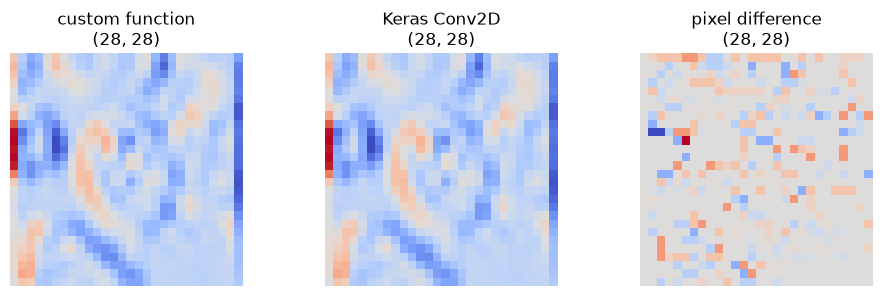

In [24]:
if tissue_available:
    kernel=filter_gallery["3x3 vertical Sobel"]
    custom_constant=apply_odd_kernel(sample_gray,kernel,padding="constant")
    builtin=tf.keras.layers.Conv2D(1,3,padding="same",use_bias=False,kernel_initializer="zeros"); builtin(tissue_train[:1]); builtin.set_weights([kernel[...,None,None]])
    builtin_same=builtin(tissue_train[:1]).numpy()[0,...,0]
    comparison=pd.DataFrame([{
        "custom operation":"correlation + constant zero border",
        "built-in operation":"Conv2D cross-correlation + same zero border",
        "max_abs_error":float(np.max(np.abs(custom_constant-builtin_same))),
        "mean_abs_error":float(np.mean(np.abs(custom_constant-builtin_same))),
        "output_shape":custom_constant.shape,
    }])
    display(comparison)
    show_maps([custom_constant,builtin_same,custom_constant-builtin_same],["custom function","Keras Conv2D","pixel difference"],cmap="coolwarm",cols=3)
    assert np.allclose(custom_constant,builtin_same,atol=1e-5)


## A1.3 Complete layer-by-layer transformation trace

**What:** Show how one medical image changes after every CNN stage, including representative channels before and after pooling.

**Why:** A shape table alone does not show information loss; paired maps make the spatial-to-vector transformation visible.


,stage,shape,meaning
0,input,"(28, 28, 1)",raw grayscale medical image
1,tissue_conv1,"(28, 28, 8)",low-level edges/textures
2,tissue_pool1,"(14, 14, 8)",spatial downsampling
3,tissue_conv2,"(14, 14, 16)",combined patterns
4,tissue_pool2,"(7, 7, 16)",spatial downsampling
5,tissue_flatten,"(784,)",flattened spatial values
6,tissue_latent,"(32,)",latent representation
7,tissue_classifier,"(8,)",class probabilities


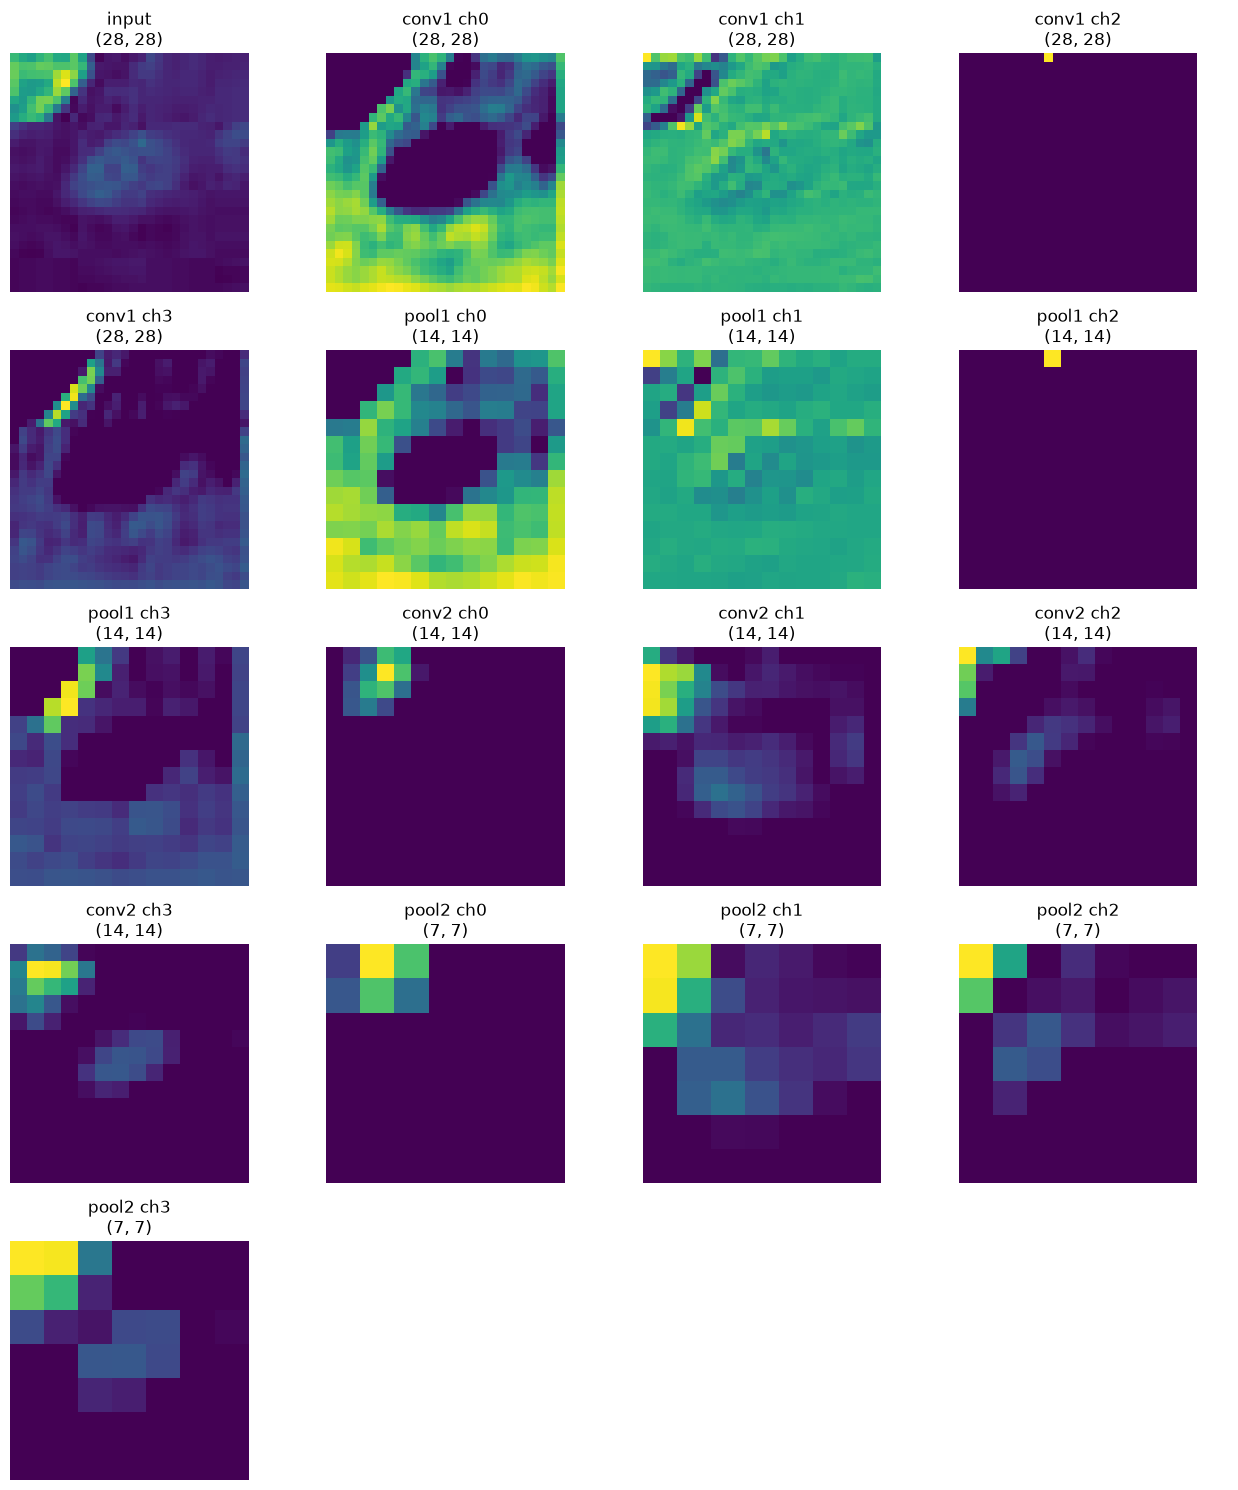

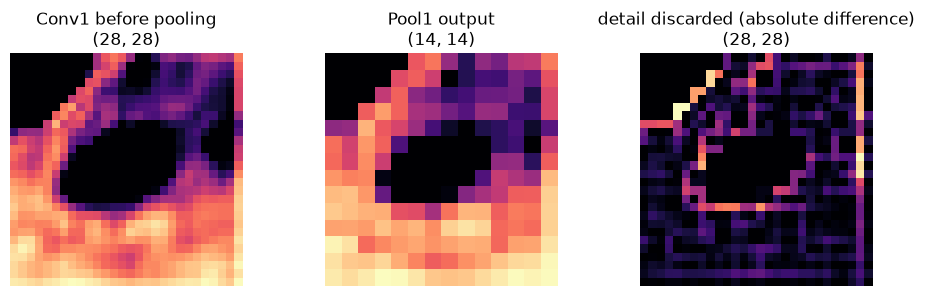

In [25]:
if tissue_available:
    tissue_trace_names=["tissue_conv1","tissue_pool1","tissue_conv2","tissue_pool2","tissue_flatten","tissue_latent","tissue_classifier"]
    tissue_trace=tf.keras.Model(tissue_model.inputs[0],[tissue_model.get_layer(n).output for n in tissue_trace_names])
    tissue_acts=dict(zip(tissue_trace_names,tissue_trace.predict(tissue_test[:1],verbose=0)))
    tissue_shape_table=pd.DataFrame([{
        "stage":"input","shape":tuple(tissue_test[:1].shape[1:]),"meaning":"raw grayscale medical image"
    }]+[{"stage":n,"shape":tuple(a.shape[1:]),"meaning":("low-level edges/textures" if "conv1" in n else "combined patterns" if "conv2" in n else "spatial downsampling" if "pool" in n else "flattened spatial values" if "flatten" in n else "latent representation" if "latent" in n else "class probabilities")} for n,a in tissue_acts.items()])
    display(tissue_shape_table)
    show_maps([tissue_test[0,...,0]]+[tissue_acts["tissue_conv1"][0,...,i] for i in range(4)]+[tissue_acts["tissue_pool1"][0,...,i] for i in range(4)]+[tissue_acts["tissue_conv2"][0,...,i] for i in range(4)]+[tissue_acts["tissue_pool2"][0,...,i] for i in range(4)], ["input"]+[f"conv1 ch{i}" for i in range(4)]+[f"pool1 ch{i}" for i in range(4)]+[f"conv2 ch{i}" for i in range(4)]+[f"pool2 ch{i}" for i in range(4)], cols=4)
    # Upsampling the pooled map is only for visual comparison; it is not a reconstruction.
    before=tissue_acts["tissue_conv1"][0,...,0]; after=tissue_acts["tissue_pool1"][0,...,0]
    after_up=np.asarray(Image.fromarray(after).resize((before.shape[1],before.shape[0]),Image.Resampling.NEAREST),dtype=np.float32)
    show_maps([before,after,abs(before-after_up)],["Conv1 before pooling","Pool1 output","detail discarded (absolute difference)"],cmap="magma",cols=3)


## A1.4 Learned kernels, flattening, latent vector, and classifier

**What:** Display learned convolution weights and the exact flattened, latent, and softmax vectors for the same medical image.

**Why:** This connects trainable filter weights to the representations used for prediction.


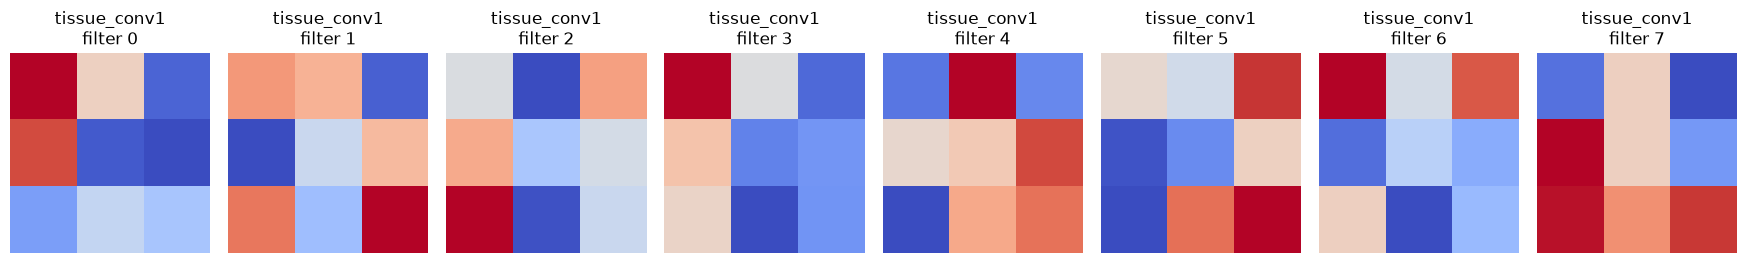

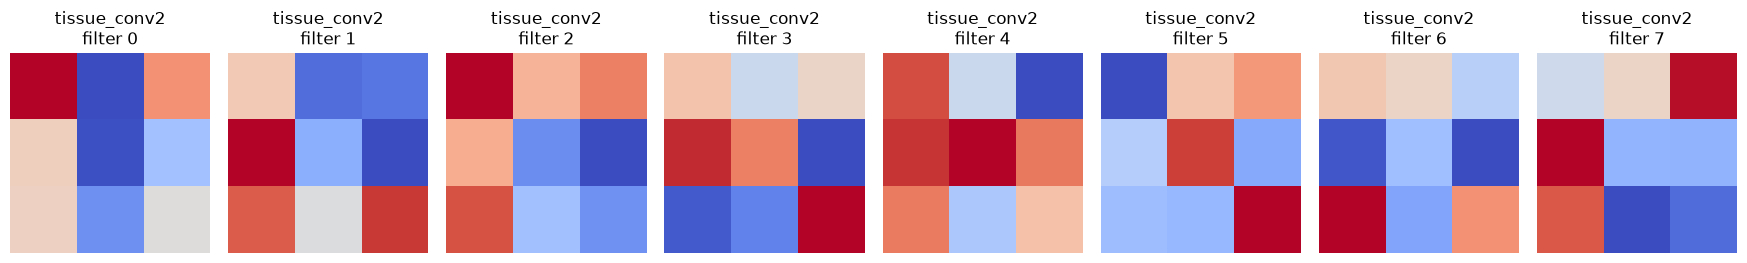

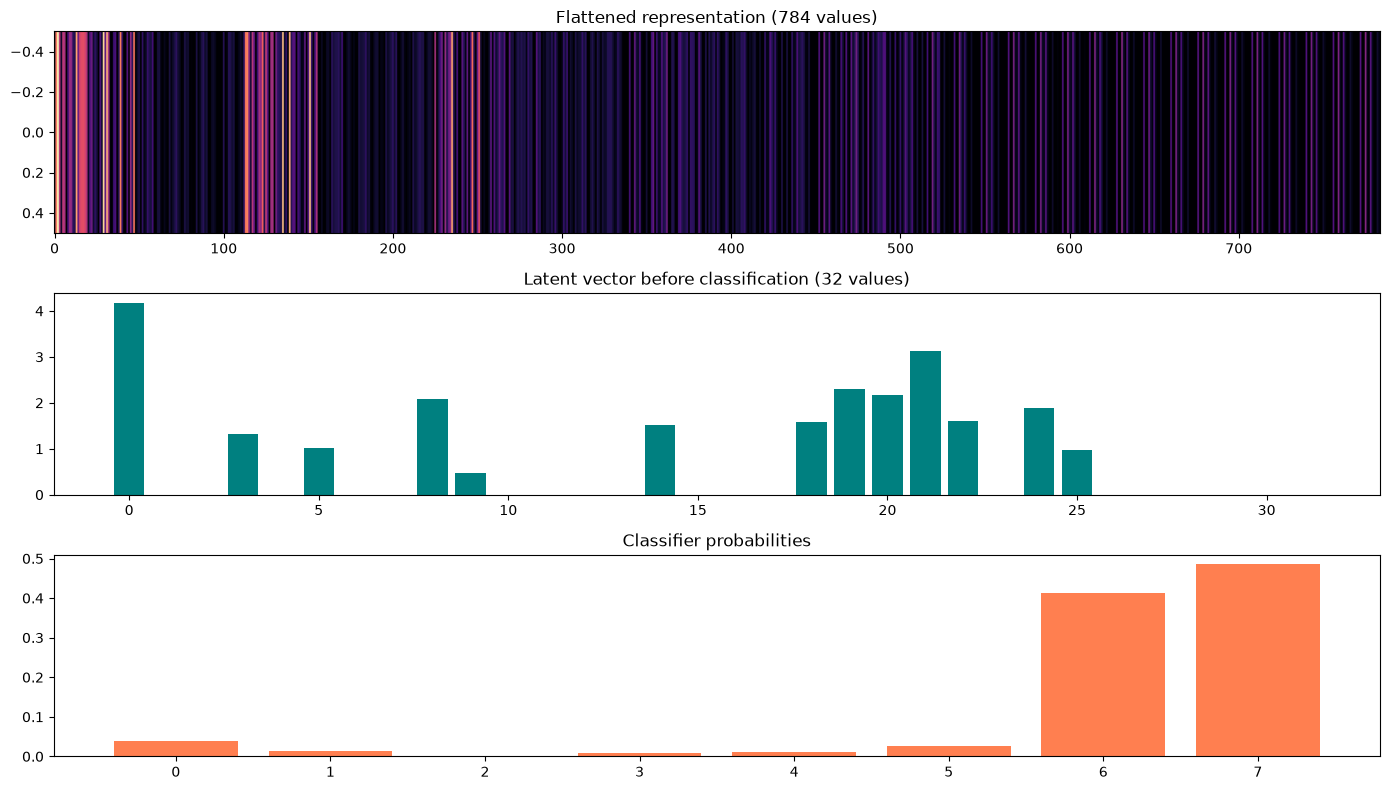

In [26]:
if tissue_available:
    for layer_name in ["tissue_conv1","tissue_conv2"]:
        weights=tissue_model.get_layer(layer_name).get_weights()[0]
        count=min(weights.shape[-1],8); fig,axes=plt.subplots(1,count,figsize=(2.2*count,2.5),squeeze=False)
        for i in range(count):
            kernel=weights[...,0,i] if weights.shape[2]==1 else weights[:,:,0,i]
            axes[0,i].imshow(kernel,cmap="coolwarm",interpolation="nearest"); axes[0,i].set_title(f"{layer_name}\nfilter {i}"); axes[0,i].axis("off")
        plt.tight_layout(); plt.show()
    flat=tissue_acts["tissue_flatten"][0]; latent=tissue_acts["tissue_latent"][0]; probs=tissue_acts["tissue_classifier"][0]
    fig,axes=plt.subplots(3,1,figsize=(14,8)); axes[0].imshow(flat[None,:],aspect="auto",cmap="magma"); axes[0].set_title(f"Flattened representation ({flat.size} values)"); axes[1].bar(np.arange(latent.size),latent,color="teal"); axes[1].set_title(f"Latent vector before classification ({latent.size} values)"); axes[2].bar(np.arange(probs.size),probs,color="coral"); axes[2].set_title("Classifier probabilities"); plt.tight_layout(); plt.show()


## A2.1 RGB filters: per-channel versus full 3D convolution

**What:** Compare separate R/G/B hand-crafted responses with a Keras filter whose kernel spans all three RGB channels.

**Why:** A grayscale filter is 2D, but an RGB Conv2D filter is `(height, width, 3)` and combines colour channels into one output map.


RGB kernel shape: (3, 3, 3) per-channel stack: (224, 224, 3) full Conv2D: (224, 224)


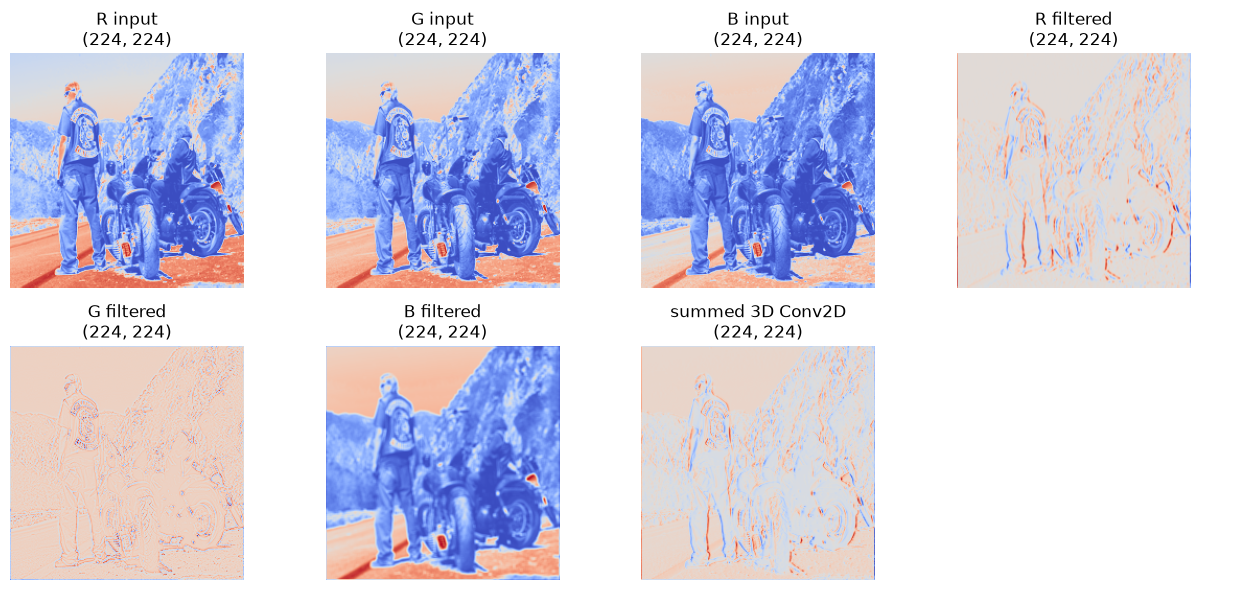

In [27]:
rgb_kernel=np.array([[[-1,0,1],[-2,0,2],[-1,0,1]]],np.float32)
# Build a 3x3x3 RGB filter with different channel weights: red edge, green texture, blue smoothing.
rgb_kernel=np.zeros((3,3,3),np.float32); rgb_kernel[:,:,0]=filter_gallery["3x3 vertical Sobel"]; rgb_kernel[:,:,1]=filter_gallery["3x3 Laplacian"]; rgb_kernel[:,:,2]=filter_gallery["3x3 box blur"]
per_channel=np.stack([apply_odd_kernel(rgb[...,i],rgb_kernel[:,:,i],padding="constant") for i in range(3)],axis=-1)
rgb_layer=tf.keras.layers.Conv2D(1,3,padding="same",use_bias=False,kernel_initializer="zeros"); rgb_layer(rgb[None]); rgb_layer.set_weights([rgb_kernel[...,None]])
rgb_builtin=rgb_layer(rgb[None]).numpy()[0,...,0]
show_maps([rgb[...,0],rgb[...,1],rgb[...,2],per_channel[...,0],per_channel[...,1],per_channel[...,2],rgb_builtin],["R input","G input","B input","R filtered","G filtered","B filtered","summed 3D Conv2D"],cmap="coolwarm",cols=4)
print("RGB kernel shape:",rgb_kernel.shape,"per-channel stack:",per_channel.shape,"full Conv2D:",rgb_builtin.shape)


## A1/A2.5 Padding, stride, pooling, and kernel-size study

**What:** Measure how kernel size, padding, stride, max pooling, and average pooling change spatial shape, information, and cost.

**Why:** These hyperparameters control detail retention, computational complexity, and receptive-field growth.


In [28]:
if tissue_available:
    experiments=[]
    for k in [1,3,5,7]:
        for padding in ["same","valid"]:
            layer=tf.keras.layers.Conv2D(4,k,padding=padding,activation="relu"); out=layer(tissue_train[:1]); experiments.append({"kernel":k,"padding":padding,"stride":1,"output_shape":tuple(out.shape[1:]),"parameters":layer.count_params()})
    for pool_name,pool in [("max",tf.keras.layers.MaxPooling2D(2)),("average",tf.keras.layers.AveragePooling2D(2))]: experiments.append({"kernel":"pool 2x2","padding":"valid","stride":2,"output_shape":tuple(pool(tissue_train[:1]).shape[1:]),"parameters":pool.count_params()})
    display(pd.DataFrame(experiments))


,kernel,padding,stride,output_shape,parameters
0,1,same,1,"(28, 28, 4)",8
1,1,valid,1,"(28, 28, 4)",8
2,3,same,1,"(28, 28, 4)",40
3,3,valid,1,"(26, 26, 4)",40
4,5,same,1,"(28, 28, 4)",104
5,5,valid,1,"(24, 24, 4)",104
6,7,same,1,"(28, 28, 4)",200
7,7,valid,1,"(22, 22, 4)",200
8,pool 2x2,valid,2,"(14, 14, 1)",0
9,pool 2x2,valid,2,"(14, 14, 1)",0


## A2.6 Explainability and receptive-field diagrams

**What:** Add Grad-CAM for the learned grayscale CNN and draw receptive-field growth for each stage.

**Why:** Grad-CAM links a prediction back to spatial evidence, while receptive fields explain why deeper maps are more contextual and less pixel-specific.


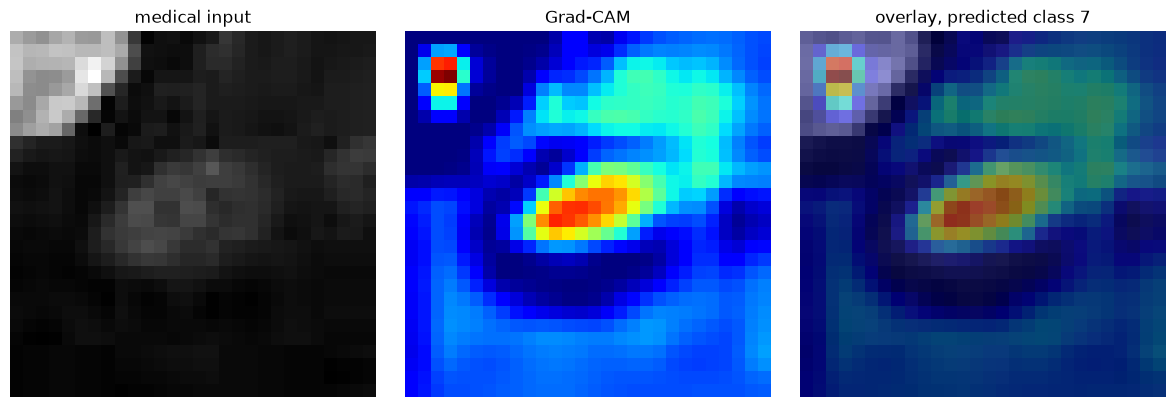

,stage,receptive_field,effective_stride
0,input,1,1
1,tissue_conv1,3,1
2,tissue_pool1,4,2
3,tissue_conv2,8,2
4,tissue_pool2,10,4


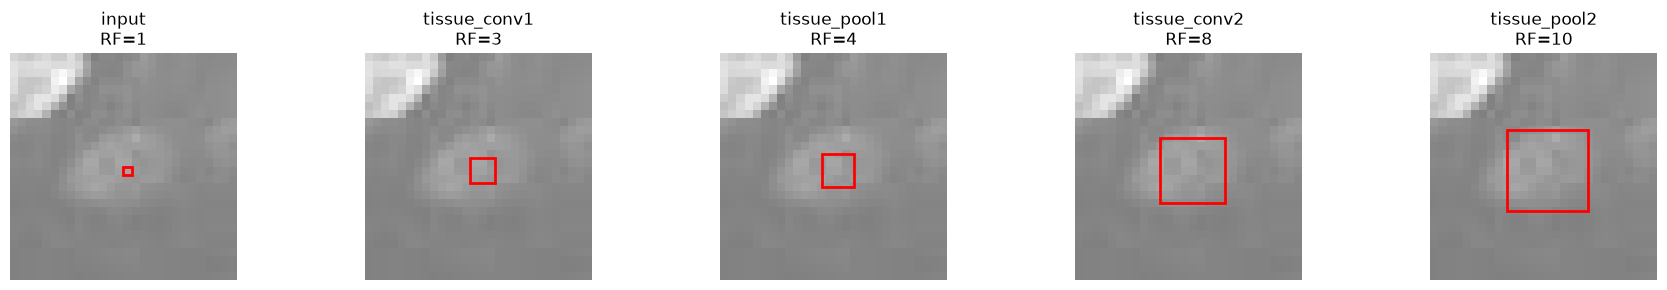

In [29]:
if tissue_available:
    grad_model=tf.keras.Model(tissue_model.inputs[0],[tissue_model.get_layer("tissue_conv2").output,tissue_model.get_layer("tissue_classifier").output])
    with tf.GradientTape() as tape:
        conv_out,pred=grad_model(tissue_test[:1]); cls=tf.argmax(pred[0]); score=pred[:,cls]
    grads=tape.gradient(score,conv_out); weights=tf.reduce_mean(grads,axis=(1,2)); cam=tf.reduce_sum(conv_out[0]*weights[0],axis=-1).numpy(); cam=np.maximum(cam,0); cam/=cam.max()+1e-8
    cam_img=np.asarray(Image.fromarray(cam).resize((tissue_test.shape[2],tissue_test.shape[1]),Image.Resampling.BILINEAR),dtype=np.float32)
    fig,axes=plt.subplots(1,3,figsize=(12,4)); axes[0].imshow(tissue_test[0,...,0],cmap="gray"); axes[0].set_title("medical input"); axes[1].imshow(cam_img,cmap="jet"); axes[1].set_title("Grad-CAM"); axes[2].imshow(tissue_test[0,...,0],cmap="gray"); axes[2].imshow(cam_img,cmap="jet",alpha=.45); axes[2].set_title(f"overlay, predicted class {int(cls)}"); [a.axis("off") for a in axes]; plt.tight_layout(); plt.show()
    rf_rows=[]; rf=1; jump=1
    for name in ["input","tissue_conv1","tissue_pool1","tissue_conv2","tissue_pool2"]:
        if name!="input":
            layer=tissue_model.get_layer(name)
            if isinstance(layer,tf.keras.layers.Conv2D): rf+=(layer.kernel_size[0]-1)*jump; jump*=layer.strides[0]
            elif isinstance(layer,tf.keras.layers.MaxPooling2D): rf+=(layer.pool_size[0]-1)*jump; jump*=layer.strides[0]
        rf_rows.append({"stage":name,"receptive_field":rf,"effective_stride":jump})
    rf_table=pd.DataFrame(rf_rows); display(rf_table)
    fig,axes=plt.subplots(1,len(rf_rows),figsize=(18,3))
    for ax,row in zip(axes,rf_rows):
        ax.imshow(tissue_test[0,...,0],cmap="gray",alpha=.5); side=min(row["receptive_field"],tissue_test.shape[1]); start=(tissue_test.shape[1]-side)/2; ax.add_patch(plt.Rectangle((start,start),side,side,fill=False,color="red",lw=2)); ax.set_title(f"{row['stage']}\nRF={row['receptive_field']}"); ax.axis("off")
    plt.tight_layout(); plt.show()


## Final CNN pipeline poster and source-notebook audit

**What:** Summarize the complete image-to-prediction pipeline and identify where every major addition from the three source notebooks now appears.

**Why:** This prevents useful self-learning work from being hidden or mistaken for an unimplemented requirement.


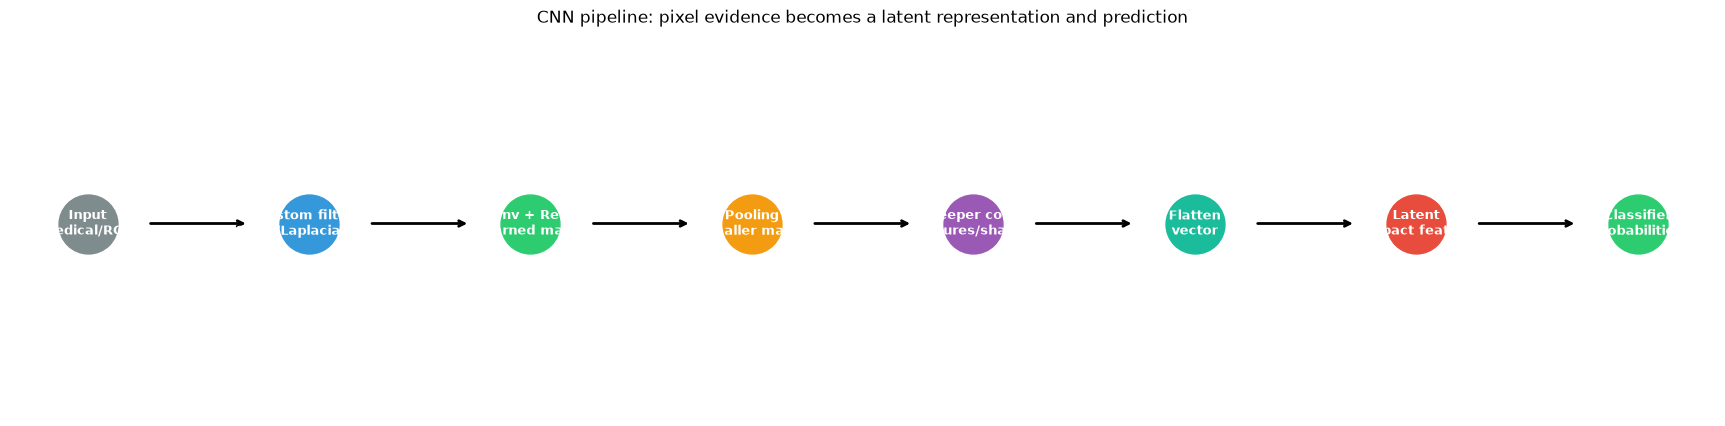

,source addition,implemented_in
0,kernel gallery and annotated weights,A1.1 filter gallery + learned-kernel section
1,custom RGB channel filters,A2 RGB filters: per-channel versus full 3D con...
2,layer-by-layer maps and pooling detail,A1.3 complete transformation trace
3,"flattened, latent, softmax visualizations",A1.4 and Part B trace
4,padding and receptive-field study,A1.1 and A2.6
5,Grad-CAM and pipeline poster,A2.6 and final poster
6,complexity and hyperparameter safeguards,"complexity tables, kernel/pooling study, Part ..."


In [30]:
fig,ax=plt.subplots(figsize=(22,5)); ax.axis("off"); stages=[("Input\nmedical/RGB", "#7f8c8d"),("Custom filters\nSobel/Laplacian/blur", "#3498db"),("Conv + ReLU\nlearned maps", "#2ecc71"),("Pooling\nsmaller maps", "#f39c12"),("Deeper conv\ntextures/shapes", "#9b59b6"),("Flatten\nvector", "#1abc9c"),("Latent\ncompact features", "#e74c3c"),("Classifier\nprobabilities", "#2ecc71")]; xs=np.linspace(.05,.95,len(stages))
for i,(label,color) in enumerate(stages):
    ax.scatter(xs[i],.5,s=1800,color=color); ax.text(xs[i],.5,label,ha="center",va="center",color="white",fontsize=9,weight="bold")
    if i<len(stages)-1: ax.annotate("",xy=(xs[i+1]-.035,.5),xytext=(xs[i]+.035,.5),arrowprops={"arrowstyle":"->","lw":2})
plt.title("CNN pipeline: pixel evidence becomes a latent representation and prediction"); plt.show()
audit=pd.DataFrame([
{"source addition":"kernel gallery and annotated weights","implemented_in":"A1.1 filter gallery + learned-kernel section"},
{"source addition":"custom RGB channel filters","implemented_in":"A2 RGB filters: per-channel versus full 3D convolution"},
{"source addition":"layer-by-layer maps and pooling detail","implemented_in":"A1.3 complete transformation trace"},
{"source addition":"flattened, latent, softmax visualizations","implemented_in":"A1.4 and Part B trace"},
{"source addition":"padding and receptive-field study","implemented_in":"A1.1 and A2.6"},
{"source addition":"Grad-CAM and pipeline poster","implemented_in":"A2.6 and final poster"},
{"source addition":"complexity and hyperparameter safeguards","implemented_in":"complexity tables, kernel/pooling study, Part B tuning"},
])
display(audit)
